# Pretrained Transfer Learning with Source Pretraining, Target Fine-Tuning, and Layer-wise PC Tracking

## Task Description
Implementation of a two-stage transfer learning pipeline based on Di et al. (2025):
1. **Target Fixed Subsets Setup**:
   - At initialization, draw and fix `SAMPLE_SIZES` instances from the target dataset `NUM_REPLICATIONS` times with fixed random seeds for reproducible target validation loss and layer-wise Projection Correlation (PC) evaluation with confidence intervals.
2. **Stage 1 (Source Pretraining)**:
   - Train a 6-layer CNN on the source dataset.
   - Early stopping on source validation loss with patience `EARLY_STOP_PATIENCE` (=5).
   - Upon trigger, run an extra `POST_EARLY_STOP_EPOCHS` (=10) control epochs.
   - At each epoch, evaluate and log: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC ($\omega_j$) with 95% CI.
   - Select best source model: by Source Val Loss or by PC generality.
3. **Stage 2 (Target Fine-Tuning across 7 Models $M_0 \dots M_6$)**:
   - Transfer first $k$ layers ($k \in \{0, 1, 2, 3, 4, 5, 6\}$).
   - Target training on fixed sample subset (`SAMPLE_SIZES`).
   - Early stopping monitored on Target Validation Loss with patience `TARGET_PATIENCE` (=5).
   - Log each epoch: Train Loss, Test Accuracy, Target Val Loss, Layer-wise PC.

## Документация по генераторам случайных чисел

В блокноте используются генераторы случайных чисел Python (`random`), NumPy (`np.random`) и PyTorch (`torch.manual_seed`, `torch.Generator`).

### 1. `setup_environment()`
1) Название функции: `setup_environment`
2) Генератор случайных чисел: функция настраивает устройство (CPU/GPU) и окружение Colab/Drive, но **не инициализирует генераторы случайных чисел самостоятельно**.



### 2. `get_experiment_params()`
1) Название функции: `get_experiment_params`
2) Генератор случайных чисел: внутри функции вызываются `random.seed(seed)`, `np.random.seed(seed)`, `torch.manual_seed(seed)`, а при наличии CUDA — `torch.cuda.manual_seed(seed)` и `torch.cuda.manual_seed_all(seed)`. Также устанавливаются `torch.backends.cudnn.deterministic = True` и `torch.backends.cudnn.benchmark = False`. Используются глобальные генераторы Python, NumPy и PyTorch.
3) Инициализация: вызывается после `setup_environment()`; параметр `seed` имеет значение по умолчанию **42** и может быть переопределён при вызове. Инициализация происходит в начале тела функции, сразу после формирования словаря `params`.
4) Число seed при запуске всего блокнота: **43** (передано явно в вызове `get_experiment_params(seed=43)` в ячейке 43; по умолчанию в функции — 42).

### 3. `select_fixed_subsets()`
1) Название функции: `select_fixed_subsets`
2) Генератор случайных чисел: создаётся локальный генератор PyTorch через `torch.Generator().manual_seed(seed)`, где `seed = base_seed + rep * 1000 + n_s`. Этот генератор передаётся в `torch.randperm(n_total, generator=gen)` для детерминированного выбора индексов подмножеств целевой выборки.
3) Инициализация: вызывается в блоке отбора фиксированных подмножеств. Параметр `base_seed` имеет значение по умолчанию **42**; для каждой репликации `rep` вычисляется अपना `seed`. Инициализация происходит в начале цикла по репликациям.
4) Число seed при запуске всего блокнота: **43** (через `params['seed']=43`, переданное в ячейке 43).

### 4. `run_stage1_pretraining()`
1) Название функции: `run_stage1_pretraining`
2) Генератор случайных чисел: внутри функции вызываются `torch.manual_seed(seed)` и `torch.cuda.manual_seed_all(seed)` для установки состояния генератора PyTorch перед началом обучения исходной модели.
3) Инициализация: вызывается на этапе 1 (предварительное обучение). `seed` берётся из `params['seed']`; инициализация происходит в начале тела функции, до создания модели и загрузки данных.
4) Число seed при запуске всего блокнота: **43** (через `params['seed']=43`, переданное в ячейке 43).

### 5. `load_experiment_data()`
1) Название функции: `load_experiment_data`
2) Генератор случайных чисел: в начале тела функции вызываются `random.seed(seed)`, `np.random.seed(seed)`, `torch.manual_seed(seed)`, `torch.cuda.manual_seed(seed)` и `torch.cuda.manual_seed_all(seed)` (при наличии CUDA). Кроме того, создаётся локальный `torch.Generator().manual_seed(seed)` и передаётся в `make_dataloaders(..., generator=generator)` для детерминированного порядка батчей.
3) Инициализация: происходит в начале тела функции, сразу после docstring и перед загрузкой данных. Параметр `seed` имеет значение по умолчанию **42** и может быть переопределён.
4) Число seed при запуске всего блокнота: **43** (через параметр `seed=43`, переданный в ячейке 43).

### 6. `run_stage2_for_analysis_epochs()`
1) Название функции: `run_stage2_for_analysis_epochs`
2) Генератор случайных чисел: в начале тела функции вызываются `random.seed(seed)`, `np.random.seed(seed)`, `torch.manual_seed(seed)`, `torch.cuda.manual_seed(seed)` и `torch.cuda.manual_seed_all(seed)` (при наличии CUDA). Параметр `seed` передаётся дальше во внутреннюю функцию `run_stage2_from_stage1_logs`.
3) Инициализация: происходит в начале тела функции, сразу после извлечения параметров из `params` и перед вызовами `run_stage2_from_stage1_logs`.
4) Число seed при запуске всего блокнота: **43** (через `params['seed']=43`, переданное в ячейке 43).


## 1. Environment Setup, Google Colab Integration & GPU Verification

**Определяет функции:** `setup_environment`


In [1]:
# Ячейка 2
import os
import sys
import time
import json
import glob
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import random

def setup_environment() -> Tuple[torch.device, int]:
    """Setup device,  and Google Colab environment / Drive mount.

    Parameters
    ----------
    seed : int
        Base random seed for reproducibility.

    Returns
    -------
    Tuple[torch.device, int]
        (device, seed) where device is cuda or cpu.
    """

    if "google.colab" in sys.modules:
        print("[Colab] Google Colab environment detected.")
        target_dir = None

        # Поиск репозитория только на Google Drive
        try:
            from google.colab import drive
            drive.mount('/content/drive')
            candidates = [
                '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2',
                '/content/drive/MyDrive/Diplom/var1_Di/code/Di2',
                '/content/drive/MyDrive/var1_Di/code/Di2',
                '/content/drive/MyDrive/code/Di2',
                '/content/drive/MyDrive/Di2',
            ]
            for cand in candidates:
                if (
                    os.path.isdir(cand)
                    and os.path.exists(os.path.join(cand, 'models.py'))
                    and os.path.exists(os.path.join(cand, 'experiment_log.py'))
                ):
                    target_dir = cand
                    break

            if target_dir is None and os.path.isdir('/content/drive/MyDrive'):
                print("[Colab] Searching for project folder in Google Drive...")
                for root, dirs, files in os.walk('/content/drive/MyDrive'):
                    if (
                        'models.py' in files
                        and 'di_algorithm.py' in files
                        and 'experiment_log.py' in files
                    ):
                        target_dir = root
                        break
        except Exception as e:
            print(f"[Colab] Google Drive search skipped/failed: {e}")

        # 3. If still not found, clone repository directly from GitHub
        # if target_dir is None:
        #     print("[Colab] Repository files not found locally or in Drive. Cloning from GitHub...")
        #     import subprocess
        #     subprocess.run(['git', 'clone', 'https://github.com/DR24DR24/Di.git', '/content/Di2'], check=False)
        #     if os.path.exists('/content/Di2/models.py'):
        #         target_dir = '/content/Di2'

        if target_dir:
            os.chdir(target_dir)
            if target_dir not in sys.path:
                sys.path.insert(0, target_dir)
            print(f"[Colab] Working directory set to: {os.getcwd()}")
        else:
            cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
            if cd not in sys.path:
                sys.path.insert(0, cd)
            print(f"[Colab] WARNING: project not found on Google Drive! Current directory: {os.getcwd()}")
    else:
        cd = os.path.dirname(os.path.abspath("__file__")) if "__file__" in locals() else os.getcwd()
        if cd not in sys.path:
            sys.path.insert(0, cd)
        print(f"[Local] Working directory: {os.getcwd()}")

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Device: {device}")
    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")


    return device


# Execute environment setup immediately when Cell 3 runs
device = setup_environment()


[Colab] Google Colab environment detected.
Mounted at /content/drive
[Colab] Working directory set to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2
Device: cpu


## 2. Experiment Parameters, Named Constants & Output Directory

**Определяет функции:** `get_experiment_params`


In [3]:
# Ячейка 4
from experiment_log import experiment_log
def get_experiment_params(
    experiment_case: str = 'imbalance',
    pc_sample_size: int = 200,
    num_replications: int = 10,
    use_real_cifar10: bool = True,
    pretrain_epochs: int = 50,
    early_stop_patience: int = 5,
    post_early_stop_epochs: int = 1,
    learning_rate_source: float = 0.001,
    target_epochs: int = 50,
    target_patience: int = 5,
    learning_rate_target: float = 0.001,
    feature_extraction: bool = True,
    ft_sample_size: Optional[int] = 1000,
    best_model_criterion: str = 'pc',
    mode: str = "4_epochs",
    notebook_name: str = "pretrained_stat",
    seed: int = 42,
) -> Dict[str, Any]:
    """Return all experiment parameters as a dictionary."""

    results_dir =  os.path.join(os.getcwd(), "pretrained_stat")

    params = {
        "experiment_case": experiment_case,
        "pc_sample_size": pc_sample_size,
        "num_replications": num_replications,
        "use_real_cifar10": use_real_cifar10,
        "pretrain_epochs": pretrain_epochs,
        "early_stop_patience": early_stop_patience,
        "post_early_stop_epochs": post_early_stop_epochs,
        "learning_rate_source": learning_rate_source,
        "target_epochs": target_epochs,
        "target_patience": target_patience,
        "learning_rate_target": learning_rate_target,
        "feature_extraction": feature_extraction,
        "ft_sample_size": ft_sample_size,
        "best_model_criterion": best_model_criterion,
        "mode": mode,
        "notebook_name": notebook_name,
        "results_dir": results_dir,
        "seed": seed,
    }

    print(f"Results Directory: {params['results_dir']}")
    print(f"Mode: {params['experiment_case']} | Sample sizes: {params['pc_sample_size']} | Replications: {params['num_replications']}")
    print(f"Post early-stopping control epochs: {params['post_early_stop_epochs']}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Random seed fixed: {seed}")

    print("\n=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===")
    for key, value in params.items():
        print(f"{key}: {value}")
    print("=======================================\n")

    return params


## 3. Data Loading, Class Splitting, and DataLoaders

**Определяет функции:** `load_experiment_data`


In [ ]:
# Ячейка 6
from models import CIFAR6CNN, create_transferred_model, set_trainable_layers
from dataset_splits import (
    split_cifar_imbalance,
    split_cifar_balance,
    generate_synthetic_transfer_dataset,
    make_dataloaders,
    create_ft_dataloader_from_subsets
)
from di_algorithm import default_eval_loss
from projection_correlation import projection_correlation, save_experiment_results
from layer_extractor import extract_layer_activations
from experiment_log import experiment_log

def load_experiment_data(params: Dict[str, Any]) -> Dict[str, Any]:
    """Load data, split into source/target, create dataloaders.

    Parameters
    ----------
    params : dict
        Dictionary with keys: experiment_case, seed, use_real_cifar10,
        n_source, n_target, batch_size, data_dir.

    Returns dict with keys: splits, loaders, target_train_x, target_train_y,
    target_test_loader, generator, num_source_classes, num_target_classes.
    """
    experiment_case = params.get("experiment_case", "imbalance")
    seed = params.get("seed", 42)
    use_real_cifar10 = params.get("use_real_cifar10", True)
    n_source = params.get("n_source", 1200)
    n_target = params.get("n_target", 800)
    batch_size = params.get("batch_size", 64)
    data_dir = params.get("data_dir", './data')

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if use_real_cifar10:
        from cifar10_experiment import load_cifar10_raw
        print("Loading CIFAR-10 dataset...")
        raw_x, raw_y = load_cifar10_raw(data_dir=data_dir)
        if experiment_case == "imbalance":
            splits = split_cifar_imbalance(raw_x, raw_y, seed=seed)
        else:
            splits = split_cifar_balance(raw_x, raw_y, seed=seed)
    else:
        print("Generating synthetic transfer dataset...")
        num_classes = 5 if experiment_case == "imbalance" else 10
        transition_layer = 3 if experiment_case == "imbalance" else 4
        splits = generate_synthetic_transfer_dataset(
            n_source=n_source, n_target=n_target,
            num_classes=num_classes,
            transition_layer=transition_layer,
            seed=seed
        )

    generator = torch.Generator().manual_seed(seed)
    loaders = make_dataloaders(splits, batch_size=batch_size, generator=generator)

    target_train_x, target_train_y = splits['target_train']
    target_test_loader = loaders['target_test']

    print(f"Source train size: {len(splits['source_train'][0])} | test: {len(splits['source_test'][0])}")
    print(f"Target train size: {len(target_train_x)} | test: {len(splits['target_test'][0])}")
    print(f"Source classes: {splits['num_source_classes']} | Target classes: {splits['num_target_classes']}")

    return {
        "splits": splits,
        "loaders": loaders,
        "target_train_x": target_train_x,
        "target_train_y": target_train_y,
        "target_test_loader": target_test_loader,
        "generator": generator,
        "num_source_classes": splits["num_source_classes"],
        "num_target_classes": splits["num_target_classes"],
    }


## 4. Selecting and Fixing Target Subsets for Projection Correlation Tracking
To calculate Projection Correlation profiles $\omega_j$ and target validation metrics with statistical confidence intervals without random sampling variance across epochs, we select and fix `SAMPLE_SIZES` items from the target training set at the start.

**Определяет функции:** `select_fixed_subsets`, `evaluate_layer_pc_profiles`, `format_pc_summary`


In [ ]:
# Ячейка 8
def select_fixed_subsets(
    x_data: torch.Tensor,
    y_data: torch.Tensor,
    pc_sample_size: int,
    num_replications: int,
    base_seed: int = 42,
    batch_size: int = 64
) -> Dict[int, List[Dict[str, Any]]]:
    """Pre-sample and fix deterministic subsets for PC and target validation."""
    n_total = x_data.shape[0]
    subsets_by_size = {}

    for n_s in [pc_sample_size]:
        subsets_by_size[n_s] = []
        eff_n = min(n_s, n_total)
        for rep in range(num_replications):
            seed = base_seed + rep * 1000 + n_s
            gen = torch.Generator().manual_seed(seed)
            indices = torch.randperm(n_total, generator=gen)[:eff_n]
            sub_x, sub_y = x_data[indices], y_data[indices]
            sub_loader = DataLoader(
                TensorDataset(sub_x, sub_y),
                batch_size=batch_size,
                shuffle=False
            )
            subsets_by_size[n_s].append({
                'rep': rep,
                'seed': seed,
                'indices': indices,
                'x': sub_x,
                'y': sub_y,
                'loader': sub_loader
            })
    return subsets_by_size


def evaluate_layer_pc_profiles(
    model: nn.Module,
    subsets_dict: Dict[int, List[Dict[str, Any]]],
    device: torch.device,
    pooling: str = 'gap',
    Debug_Info: int = 0,
    epoch: int = 0,
    output_dir: str = "debug_results",
    one_hot: bool = False,
    num_classes: Optional[int] = None
) -> Tuple[Dict[int, Dict[str, Dict[str, float]]], Dict[int, Dict[str, Dict[str, float]]]]:
    """Compute layer-wise PC on the pre-fixed subsets across replications."""
    model.eval()
    layer_names = CIFAR6CNN.LAYER_NAMES
    ipc_summary_by_size = {}
    pc_summary_by_size = {}
    for n_s, rep_list in subsets_dict.items():
        layer_rep_values = {l: [] for l in layer_names}
        layer_ips = {l: [] for l in layer_names}
        for item in rep_list:
            acts, labels = extract_layer_activations(
                model=model,
                dataloader=item['loader'],
                layer_names=layer_names,
                pooling=pooling,
                device=device,
                max_samples=n_s
            )
            for l in layer_names:
                if one_hot and num_classes is not None:
                    labels_one_hot = torch.zeros(len(labels), num_classes, device=device)
                    labels_one_hot.scatter_(1, labels.unsqueeze(1), 1.0)
                    labels_for_pc = labels_one_hot
                else:
                    labels_for_pc = labels
                pc_val = projection_correlation(acts[l], labels_for_pc, mode='pcor')
                ipc_val = projection_correlation(acts[l], labels_for_pc, mode='ipcor')
                layer_rep_values[l].append(float(pc_val))
                layer_ips[l].append(float(ipc_val))
                if Debug_Info == 1:
                    experiment_name = f"CNN6_{epoch}_{l}"
                    save_experiment_results(
                        experiment_name=experiment_name,
                        X=acts[l],
                        Y=labels,
                        pc={'PC': float(pc_val)},
                        output_dir=output_dir,
                    )
        stats = {}
        for l in layer_names:
            arr = np.array(layer_rep_values[l])
            stats[l] = {
                'mean': float(np.mean(arr)),
                'std': float(np.std(arr)),
                'values': [float(v) for v in arr]
            }
        pc_summary_by_size[n_s] = stats
        ipc_stats = {}
        for l in layer_names:
            ipc_arr = np.array(layer_ips[l])
            ipc_stats[l] = {
                'mean': float(np.mean(ipc_arr)),
                'std': float(np.std(ipc_arr)),
                'values': [float(v) for v in ipc_arr]
            }
        ipc_summary_by_size[n_s] = ipc_stats
    return pc_summary_by_size, ipc_summary_by_size


def format_pc_summary(
    pc_stats: Dict[int, Dict[str, Dict[str, float]]],
    ipc_stats: Optional[Dict[int, Dict[str, Dict[str, float]]]] = None,
    target_size: Optional[int] = None
) -> str:
    """Format PC stats as a readable string for logging."""
    if target_size is None:
        target_size = list(pc_stats.keys())[0] if pc_stats else 0
    stats = pc_stats.get(target_size, {})
    parts = []
    for l in CIFAR6CNN.LAYER_NAMES:
        if l in stats:
            parts.append(f"{l}={stats[l]['mean']:.3f}\u00b1{stats[l]['std']:.3f}")
    if ipc_stats is not None:
        ipc = ipc_stats.get(target_size, {})
        ipc_parts = []
        for l in CIFAR6CNN.LAYER_NAMES:
            if l in ipc:
                ipc_parts.append(f"{l}={ipc[l]['mean']:.3f}\u00b1{ipc[l]['std']:.3f}")
        if ipc_parts:
            parts.append("IPC: " + " | ".join(ipc_parts))
    return " | ".join(parts)


## 5. Stage 1: Source Pretraining with Early Stopping and Post-Patience Control
- Monitored metric: **Source Validation Loss**.
- Upon triggering early stopping, training continues for **`POST_EARLY_STOP_EPOCHS`** control epochs.
- Model selection based on `best_model_criterion` ('pc', 'ipc', 'source_val_loss', 'frankenstein').
- Logged each epoch: Train Loss, Source Test Accuracy, Source Validation Loss, Target Validation Loss, Layer-wise PC.

**Определяет функции:** `run_stage1_pretraining`


In [8]:
# Ячейка 10
@experiment_log(
    keys=[
        "best_model_criterion", "early_stop_patience", "experiment_case",
        "learning_rate_source", "num_replications", "post_early_stop_epochs",
        "pretrain_epochs", "pc_sample_size", "seed",
    ],
    param="params",
    root=None,
)
def run_stage1_pretraining(params, runtime, log_path=None) -> Dict[str, Any]:
    """Run Stage 1: Source pretraining with early stopping and model selection.

    All artifacts are written only to ``log_path`` provided by the
    ``experiment_log`` decorator. No files are written outside of it.

    1.1 Early stopping (AND logic across 3 conditions):
        - Condition 1: Minimum validation loss + early_stop_patience epochs (5 epochs)
        - Condition 2: Maximum PC + early_stop_patience epochs (5 epochs)
        - Condition 3: Maximum IPC + early_stop_patience epochs (5 epochs)
        Training continues until ALL THREE conditions are met simultaneously.

    1.2 Logging directory:
        Provided by the decorator as ``log_path``.
        Re-running with identical parameters overwrites existing files in place.

    1.3 Model logs for all epochs:
        Saved to stage1_model_history.json and pretrained_model.pt inside ``log_path``.

    1.4 Launch parameters:
        Saved to launch_parameters.txt inside ``log_path``.

    1.5 CSV table with PC and IPC:
        Saved to pc_ipc_layer_profiles.csv inside ``log_path``.
    """
    device = runtime["device"]
    loaders = runtime["loaders"]
    num_source_classes = runtime["num_source_classes"]
    fixed_target_subsets = runtime["fixed_target_subsets"]
    num_target_classes = runtime["num_target_classes"]
    target_test_loader = runtime.get("target_test_loader")
    seed = params["seed"]
    pc_sample_size = params["pc_sample_size"]
    pretrain_epochs = params.get("pretrain_epochs", 50)
    early_stop_patience = params.get("early_stop_patience", 5)
    post_early_stop_epochs = params.get("post_early_stop_epochs", 1)
    learning_rate_source = params.get("learning_rate_source", 0.001)
    best_model_criterion = params.get("best_model_criterion", 'pc')
    experiment_case = params.get("experiment_case", 'imbalance')
    num_replications = params.get("num_replications", 0)
    import csv

    num_reps = len(fixed_target_subsets.get(pc_sample_size, [])) if fixed_target_subsets else 0

    # 1.4 Save launch parameters in readable key-value format
    launch_params = {
        'best_model_criterion': best_model_criterion,
        'early_stop_patience': early_stop_patience,
        'experiment_case': experiment_case,
        'learning_rate_source': learning_rate_source,
        'num_replications': int(num_reps),
        'post_early_stop_epochs': post_early_stop_epochs,
        'pretrain_epochs': pretrain_epochs,
        'pc_sample_size': pc_sample_size,
        'seed': seed,
    }
    launch_params['device'] = str(device)
    launch_params['top_level_function'] = 'run_stage1_pretraining'
    launch_params['short_hash'] = log_path.name
    launch_params["results_dir"] = params["results_dir"]
    launch_params['log_dir'] = str(log_path)
    launch_params['loaders'] = {
        name: {
            'dataset_size': len(getattr(loader, 'dataset', [])),
            'batch_size': getattr(loader, 'batch_size', None),
        }
        for name, loader in loaders.items()
    }
    launch_params['fixed_target_subsets'] = {
        'pc_sample_size': sorted(int(size) for size in fixed_target_subsets),
        'replications_by_sample_size': {
            str(size): len(reps) for size, reps in fixed_target_subsets.items()
        },
    }
    launch_params['target_test_loader'] = None if target_test_loader is None else {
        'dataset_size': len(getattr(target_test_loader, 'dataset', [])),
        'batch_size': getattr(target_test_loader, 'batch_size', None),
    }

    params_txt_path = str(log_path / "launch_parameters.txt")
    with open(params_txt_path, 'w', encoding='utf-8') as f_params:
        f_params.write("=" * 60 + "\n")
        f_params.write("STAGE 1 LAUNCH PARAMETERS\n")
        f_params.write("=" * 60 + "\n")
        for k in sorted(launch_params.keys()):
            f_params.write(f"{k:<25}: {launch_params[k]}\n")
        f_params.write("=" * 60 + "\n")

    params_json_path = str(log_path / "launch_parameters.json")
    with open(params_json_path, 'w', encoding='utf-8') as f_pjson:
        json.dump(launch_params, f_pjson, indent=2, default=str)

    # 1.5 Setup CSV file for PC and IPC layer profiles
    csv_path = str(log_path / "pc_ipc_layer_profiles.csv")
    layer_names = CIFAR6CNN.LAYER_NAMES
    csv_fieldnames = ['epoch', 'dataset_id'] + [f'pc_{l}' for l in layer_names] + [f'ipc_{l}' for l in layer_names]
    csv_rows = []

    print("Stage 1.4")
    print("=" * 75)
    print("[Stage 1] Pretraining 6-layer CNN on Source Dataset")
    print(f"Log directory: {log_path}")
    print(f"Early stop patience: {early_stop_patience} epochs (val_loss min + {early_stop_patience} AND PC max + {early_stop_patience} AND IPC max + {early_stop_patience})")
    print(f"Post-early-stop control: {post_early_stop_epochs} epochs")
    print("=" * 75)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    source_model = CIFAR6CNN(num_classes=num_source_classes).to(device)
    optimizer = torch.optim.RMSprop(source_model.parameters(), lr=learning_rate_source, alpha=0.9)
    criterion = nn.CrossEntropyLoss()

    stage1_history = []
    epoch_states = []

    best_s_val_loss = float('inf')
    best_val_loss_epoch = 1
    best_source_state = None

    best_pc_epoch = 1
    best_ipc_epoch = 1
    best_pc_value = float('-inf')
    best_ipc_value = float('-inf')

    early_stop_triggered = False
    early_stop_epoch = None
    extra_epochs_left = post_early_stop_epochs
    debug_saved = False

    ep = 0
    while True:
        ep += 1
        time_0 = time.perf_counter()
        # Training pass
        source_model.train()
        tr_loss = 0.0
        for x, y in loaders['source_train']:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = source_model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * x.size(0)
        avg_train_loss = tr_loss / len(loaders['source_train'].dataset)
        time_1 = time.perf_counter()
        if 1 == ep:
            print(f"train time: {time_1 - time_0:.3f}s")

        # Source validation & test accuracy
        s_val_loss, s_test_acc = default_eval_loss(source_model, loaders['source_test'], criterion, device)
        time_2 = time.perf_counter()
        if 1 == ep:
            print(f"eval_loss: {time_2 - time_1:.3f}s")

        # Target validation loss on target test set (if compatible)
        if target_test_loader is not None and num_source_classes == num_target_classes:
            try:
                t_val_loss, _ = default_eval_loss(source_model, target_test_loader, criterion, device)
            except Exception:
                t_val_loss = 0.0
        else:
            t_val_loss = 0.0

        # Layer-wise Projection Correlation on fixed subsets
        if (early_stop_triggered or ep == 1) and not debug_saved:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                epoch=ep, Debug_Info=1,
                output_dir=str(log_path),
                one_hot=True, num_classes=num_target_classes
            )
            debug_saved = True
        else:
            pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                source_model, fixed_target_subsets, device=device,
                one_hot=True, num_classes=num_target_classes
            )
        pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=pc_sample_size)
        time_3 = time.perf_counter()
        if 1 == ep:
            print(f"PC evaluation: {time_3 - time_2:.3f}s")

        # 1.5 Record PC and IPC values into CSV table rows:
        # 1) Per-dataset rows (replications 0 .. N-1)
        sub_list = fixed_target_subsets.get(pc_sample_size, [])
        for rep_idx in range(len(sub_list)):
            row = {'epoch': ep, 'dataset_id': rep_idx}
            for l in layer_names:
                row[f'pc_{l}'] = pc_stats[pc_sample_size][l]['values'][rep_idx]
                row[f'ipc_{l}'] = ipc_stats[pc_sample_size][l]['values'][rep_idx]
            csv_rows.append(row)

        # 2) Mean across datasets (-1)
        row_mean = {'epoch': ep, 'dataset_id': -1}
        for l in layer_names:
            row_mean[f'pc_{l}'] = pc_stats[pc_sample_size][l]['mean']
            row_mean[f'ipc_{l}'] = ipc_stats[pc_sample_size][l]['mean']
        csv_rows.append(row_mean)

        # 3) Error / uncertainty across datasets (-2)
        row_err = {'epoch': ep, 'dataset_id': -2}
        for l in layer_names:
            row_err[f'pc_{l}'] = pc_stats[pc_sample_size][l]['std']
            row_err[f'ipc_{l}'] = ipc_stats[pc_sample_size][l]['std']
        csv_rows.append(row_err)

        # Update CSV on disk (updated continuously)
        with open(csv_path, 'w', newline='', encoding='utf-8') as f_csv:
            writer = csv.DictWriter(f_csv, fieldnames=csv_fieldnames)
            writer.writeheader()
            writer.writerows(csv_rows)

        # Track PC and IPC for early stopping & model selection
        pc_means = [pc_stats[pc_sample_size][l]['mean'] for l in layer_names]
        ipc_means = [ipc_stats[pc_sample_size][l]['mean'] for l in layer_names]
        current_pc = max(pc_means)
        current_ipc = max(ipc_means)

        if current_pc > best_pc_value:
            best_pc_value = current_pc
            best_pc_epoch = ep

        if current_ipc > best_ipc_value:
            best_ipc_value = current_ipc
            best_ipc_epoch = ep

        if s_val_loss < best_s_val_loss:
            best_s_val_loss = s_val_loss
            best_val_loss_epoch = ep

        # 1.1 Check early stopping conditions (AND logic across 3 conditions)
        cond1 = (ep - best_val_loss_epoch) >= early_stop_patience
        cond2 = (ep - best_pc_epoch) >= early_stop_patience
        cond3 = (ep - best_ipc_epoch) >= early_stop_patience
        all_conditions_met = cond1 and cond2 and cond3

        # Save model state dict for this epoch
        epoch_states.append({k: v.cpu().clone() for k, v in source_model.state_dict().items()})

        # Append to history
        prefix_tag = "[Control]" if early_stop_triggered else "[Pretrain]"
        print(f"{prefix_tag} Epoch {ep:02d}/{pretrain_epochs:02d} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Source Test Acc: {s_test_acc * 100:.1f}% | "
              f"Source Val Loss: {s_val_loss:.4f} (best: {best_s_val_loss:.4f} @ ep {best_val_loss_epoch}) | "
              f"PC: {current_pc:.4f} (best: {best_pc_value:.4f} @ ep {best_pc_epoch}) | "
              f"IPC: {current_ipc:.4f} (best: {best_ipc_value:.4f} @ ep {best_ipc_epoch}) | "
              f"Patience: ValLoss={ep - best_val_loss_epoch}/{early_stop_patience}, "
              f"PC={ep - best_pc_epoch}/{early_stop_patience}, "
              f"IPC={ep - best_ipc_epoch}/{early_stop_patience}")

        stage1_history.append({
            'epoch': ep,
            'train_loss': float(avg_train_loss),
            'source_val_loss': float(s_val_loss),
            'source_test_acc': float(s_test_acc * 100.0),
            'target_val_loss': float(t_val_loss),
            'current_pc': float(current_pc),
            'current_ipc': float(current_ipc),
            'best_s_val_loss': float(best_s_val_loss),
            'best_val_loss_epoch': int(best_val_loss_epoch),
            'best_pc_value': float(best_pc_value),
            'best_pc_epoch': int(best_pc_epoch),
            'best_ipc_value': float(best_ipc_value),
            'best_ipc_epoch': int(best_ipc_epoch),
            'cond1_val_loss_met': bool(cond1),
            'cond2_pc_met': bool(cond2),
            'cond3_ipc_met': bool(cond3),
            'all_conditions_met': bool(all_conditions_met),
            'pc_profiles': pc_stats,
            'ipc_profiles': ipc_stats,
            'is_control_phase': bool(early_stop_triggered)
        })

        # Persist every epoch's weights so the full model trajectory is reproducible.
        epoch_models_path = str(log_path / "stage1_epoch_models.pt")
        torch.save(epoch_states, epoch_models_path)

        # 1.3 Save model metrics history to disk on every epoch
        history_save_path = str(log_path / "stage1_model_history.json")
        with open(history_save_path, 'w', encoding='utf-8') as f_hist:
            json.dump({
                'stage': 'stage1_pretraining',
                'experiment_case': experiment_case,
                'top_level_function': 'run_stage1_pretraining',
                        'early_stop_epoch': early_stop_epoch,
                'early_stop_triggered': early_stop_triggered,
                'post_early_stop_epochs': post_early_stop_epochs,
                'best_s_val_loss': float(best_s_val_loss),
                'best_val_loss_epoch': int(best_val_loss_epoch),
                'best_pc_value': float(best_pc_value),
                'best_pc_epoch': int(best_pc_epoch),
                'best_ipc_value': float(best_ipc_value),
                'best_ipc_epoch': int(best_ipc_epoch),
                'best_model_criterion': best_model_criterion,
                'epochs_trained': len(stage1_history),
                'history': stage1_history
            }, f_hist, indent=2)

        # 1.1 Early stopping trigger check: all 3 conditions must be satisfied
        if not early_stop_triggered:
            if all_conditions_met:
                early_stop_triggered = True
                early_stop_epoch = ep
                print(f"\n>>> [Early Stop Triggered] at epoch {ep}: all 3 conditions met (AND logic).")
                print(f"    1) Min Val Loss + {early_stop_patience} epochs: met ({ep - best_val_loss_epoch} epochs since min {best_s_val_loss:.4f} at epoch {best_val_loss_epoch})")
                print(f"    2) Max PC + {early_stop_patience} epochs: met ({ep - best_pc_epoch} epochs since max {best_pc_value:.4f} at epoch {best_pc_epoch})")
                print(f"    3) Max IPC + {early_stop_patience} epochs: met ({ep - best_ipc_epoch} epochs since max {best_ipc_value:.4f} at epoch {best_ipc_epoch})")
                if post_early_stop_epochs > 0:
                    print(f">>> Running {post_early_stop_epochs} additional control epochs...\n")
                else:
                    print(">>> Stopping Stage 1 pretraining.\n")
                    break
        else:
            extra_epochs_left -= 1
            if extra_epochs_left <= 0:
                print(f"\n>>> Completed {post_early_stop_epochs} post-early-stop control epochs. Stopping Stage 1.\n")
                break

    # === Model selection based on best_model_criterion ===
    if best_model_criterion == 'source_val_loss':
        if best_val_loss_epoch is not None and best_val_loss_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_val_loss_epoch - 1]
        print(f"Best model selected by Source Val Loss (epoch {best_val_loss_epoch}, min loss={best_s_val_loss:.4f})")
    elif best_model_criterion == 'pc':
        if best_pc_epoch is not None and best_pc_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_pc_epoch - 1]
        print(f"Best model selected by PC (epoch {best_pc_epoch}, max PC={best_pc_value:.4f})")
    elif best_model_criterion == 'ipc':
        if best_ipc_epoch is not None and best_ipc_epoch <= len(epoch_states):
            best_source_state = epoch_states[best_ipc_epoch - 1]
        print(f"Best model selected by IPC (epoch {best_ipc_epoch}, max IPC={best_ipc_value:.4f})")
    elif best_model_criterion == 'frankenstein':
        pc_per_epoch = []
        for h in stage1_history:
            pc_per_epoch.append(h['pc_profiles'][pc_sample_size])

        selected_epochs = {}
        selected_epochs['conv1'] = max(range(len(epoch_states)), key=lambda e: pc_per_epoch[e]['conv1']['mean'])
        for j in range(1, len(layer_names)):
            prev_layer = layer_names[j-1]
            curr_layer = layer_names[j]
            selected_epochs[curr_layer] = max(range(len(epoch_states)), key=lambda e: abs(pc_per_epoch[e][prev_layer]['mean'] - pc_per_epoch[e][curr_layer]['mean']))

        frankenstein_state_dict = {}
        for j, layer_name in enumerate(layer_names):
            src_epoch = selected_epochs[layer_name]
            prefixes = (f'layers.{j}.', f'{layer_name}.')
            for key, value in epoch_states[src_epoch].items():
                if key.startswith(prefixes):
                    frankenstein_state_dict[key] = value.clone()
        for key, value in epoch_states[-1].items():
            if key.startswith('classifier'):
                frankenstein_state_dict[key] = value.clone()

        best_source_state = frankenstein_state_dict
        print(f"Frankenstein model assembled: layer epochs = {selected_epochs}")
    else:
        raise ValueError(f"Unknown best_model_criterion: {best_model_criterion}")

    # 1.3 Save model checkpoint to log_path
    model_save_path = str(log_path / "pretrained_model.pt")
    torch.save({
        'best_state_dict': best_source_state,
        'final_state_dict': source_model.state_dict(),
        'early_stop_epoch': early_stop_epoch,
        'best_s_val_loss': float(best_s_val_loss),
        'best_val_loss_epoch': int(best_val_loss_epoch),
        'best_pc_value': float(best_pc_value),
        'best_pc_epoch': int(best_pc_epoch),
        'best_ipc_value': float(best_ipc_value),
        'best_ipc_epoch': int(best_ipc_epoch),
        'best_model_criterion': best_model_criterion,
    }, model_save_path)
    print(f"Pretrained model checkpoint saved to: {model_save_path}")

    print(f"Stage 1 artifacts saved in: {log_path}")
    print(f"  - Model checkpoint: {model_save_path}")
    print(f"  - Metrics history : {history_save_path}")
    print(f"  - Launch params   : {params_txt_path}")
    print(f"  - PC/IPC CSV table: {csv_path}")

    return {
        'source_model': source_model,
        'best_source_state': best_source_state,
        'stage1_history': stage1_history,
        'early_stop_epoch': early_stop_epoch,
        'best_s_val_loss': best_s_val_loss,
        'best_val_loss_epoch': best_val_loss_epoch,
        'best_pc_value': best_pc_value,
        'best_pc_epoch': best_pc_epoch,
        'best_ipc_value': best_ipc_value,
        'best_ipc_epoch': best_ipc_epoch,
        'model_save_path': str(model_save_path),
        'epoch_models_path': str(epoch_models_path),
        'history_save_path': str(history_save_path),
        'log_path': str(log_path),
        'csv_path': str(csv_path),
        'params_path': str(params_txt_path),
    }


## 6. Stage 1 Visualizations: Training Dynamics and Layer-wise PC Evolution

**Определяет функции:** `plot_stage1_visualizations`


In [ ]:
# Ячейка 12
def plot_stage1_visualizations(
    stage1_history: List[Dict[str, Any]],
    pc_sample_size: int,
    experiment_case: str = 'imbalance',
    early_stop_epoch: Optional[int] = None,
    post_early_stop_epochs: int = 1,
    log_path=None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 1 training curves and PC evolution."""
    epochs_arr = [h['epoch'] for h in stage1_history]
    tr_loss_arr = [h['train_loss'] for h in stage1_history]
    s_val_loss_arr = [h['source_val_loss'] for h in stage1_history]
    t_val_loss_arr = [h['target_val_loss'] for h in stage1_history]
    s_acc_arr = [h['source_test_acc'] for h in stage1_history]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Losses
    axes[0].plot(epochs_arr, tr_loss_arr, 'o-', color='#1f77b4', label='Source Train Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, s_val_loss_arr, 's-', color='#d62728', label='Source Val Loss', linewidth=2, markersize=4)
    axes[0].plot(epochs_arr, t_val_loss_arr, '^--', color='#9467bd', label='Target Val Loss', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[0].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[0].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange', label=f'+{post_early_stop_epochs} Control Epochs')
    axes[0].set_xlabel('Epoch', fontweight='bold')
    axes[0].set_ylabel('Loss', fontweight='bold')
    axes[0].set_title('Stage 1: Training & Validation Losses', fontweight='bold')
    axes[0].grid(True, linestyle=':', alpha=0.6)
    axes[0].legend()

    # Plot 2: Source Accuracy
    axes[1].plot(epochs_arr, s_acc_arr, 'o-', color='#2ca02c', label='Source Test Accuracy', linewidth=2, markersize=4)
    if early_stop_epoch:
        axes[1].axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        axes[1].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color='orange')
    axes[1].set_xlabel('Epoch', fontweight='bold')
    axes[1].set_ylabel('Accuracy (%)', fontweight='bold')
    axes[1].set_title('Stage 1: Source Classification Accuracy', fontweight='bold')
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    curves_path = os.path.join(log_path, "stage1_curves.png")
    plt.savefig(curves_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig)
    print(f"Stage 1 training curves saved to: {curves_path}")

    # Plot 3: Projection Correlation Evolution per Layer
    fig_pc = plt.figure(figsize=(12, 6))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    for l_idx, layer in enumerate(layer_names):
        means = [h['pc_profiles'][pc_sample_size][layer]['mean'] for h in stage1_history]
        stds = [h['pc_profiles'][pc_sample_size][layer]['std'] for h in stage1_history]
        plt.errorbar(
            epochs_arr, means, yerr=stds,
            fmt='o-', color=cmap(l_idx),
            linewidth=2, markersize=4, capsize=3,
            label=f'{layer}'
        )

    if early_stop_epoch:
        plt.axvline(early_stop_epoch, color='black', linestyle=':', linewidth=2, label=f'Early Stop (ep {early_stop_epoch})')
        plt.axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.1, color='orange')

    plt.xlabel('Pretraining Epoch', fontweight='bold', fontsize=11)
    plt.ylabel(f'Projection Correlation (n={pc_sample_size})', fontweight='bold', fontsize=11)
    plt.title(f'Stage 1: Layer-wise PC Evolution over Pretraining Epochs ({experiment_case.upper()} Case)', fontweight='bold', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()

    pc_evolution_path = os.path.join(log_path, "stage1_pc_evolution.png")
    plt.savefig(pc_evolution_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig_pc)
    print(f"Stage 1 PC evolution plot saved to: {pc_evolution_path}")

    return {
        "curves_path": curves_path,
        "pc_evolution_path": pc_evolution_path
    }


## 7. Stage 2: Target Fine-Tuning on Fixed SAMPLE_SIZES with Early Stopping (All 7 Cases: $M_0 \dots M_6$)
- Fine-tune all 7 candidate transferred models $M_k$ ($k \in \{0, 1, 2, 3, 4, 5, 6\}$) using the fixed `SAMPLE_SIZES` target training subset.
- Monitored metric: **Target Validation Loss** on the full target test set (`loaders['target_test']`).
- Two-phase training: Feature Extraction (first $k$ layers frozen) followed by Fine-Tuning (all layers unfrozen) if feature extraction is enabled.

**Определяет функции:** `run_stage2_finetuning`


In [ ]:
# Ячейка 14
@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "ft_sample_size",
        "target_epochs", "target_patience", "learning_rate_target",
        "feature_extraction", "seed", "source_epoch",
    ],
    param="params",
    root=None,
)
def run_stage2_finetuning(params, runtime, log_path=None) -> Dict[str, Any]:
    """Run Stage 2: Target fine-tuning on all 7 candidate models M_0...M_6."""
    best_source_state = runtime.get("best_source_state")
    source_model = runtime["source_model"]
    loaders = runtime["loaders"]
    target_test_loader = runtime["target_test_loader"]
    fixed_target_subsets = runtime["fixed_target_subsets"]
    device = runtime["device"]
    target_train_x = runtime["target_train_x"]
    target_train_y = runtime["target_train_y"]
    num_target_classes = runtime["num_target_classes"]
    generator = runtime.get("generator")
    pc_sample_size = params.get("pc_sample_size", 200)
    ft_sample_size = params.get("ft_sample_size")
    target_epochs = params.get("target_epochs", 50)
    target_patience = params.get("target_patience", 5)
    learning_rate_target = params.get("learning_rate_target", 0.001)
    feature_extraction = params.get("feature_extraction", True)
    experiment_case = params.get("experiment_case", "imbalance")
    seed = params.get("seed", 42)
    calculate_pc_ipc = params.get("calculate_pc_ipc", True)
    source_epoch = params.get("source_epoch")
    print("=" * 75)
    print("[Stage 2] Target Fine-Tuning on Fixed SAMPLE_SIZES for All 7 Cases (M_0 ... M_6)")
    print(f"Fixed sample size: n={pc_sample_size} | Early stopping patience: {target_patience} | Max epochs: {target_epochs}")
    print("=" * 75)

    ft_sample_size = ft_sample_size if ft_sample_size is not None else pc_sample_size
    target_train_subset_loader = create_ft_dataloader_from_subsets(
        fixed_target_subsets=fixed_target_subsets,
        target_train_x=target_train_x,
        target_train_y=target_train_y,
        sample_size=pc_sample_size,
        ft_sample_size=ft_sample_size,
        batch_size=64,
        seed=seed,
        generator=generator,
    )
    target_criterion = nn.CrossEntropyLoss()
    stage2_results = {}

    for k in range(0, 7):
        model_name = f"M_{k}"
        print("\n" + "=" * 75)
        print(f"[Stage 2] Model {model_name} (transferred k={k} layers from pre-trained source model)")
        print(f"Fine-tuning on fixed target subset (n={pc_sample_size}), monitored metric: Target Validation Loss")
        print("=" * 75)

        # Load best checkpoint from Stage 1 into source_model before transferring layers
        if best_source_state is not None:
            source_model.load_state_dict(best_source_state)

        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        target_model = create_transferred_model(
            pretrained_model=source_model,
            k=k,
            num_target_classes=num_target_classes,
            freeze_transferred=feature_extraction
        ).to(device)
        set_trainable_layers(target_model, k_freeze=k if feature_extraction else 0)
        initial_val_loss, initial_accuracy = default_eval_loss(
            target_model, target_test_loader, nn.CrossEntropyLoss(), device
        )
        initial_accuracy = float(initial_accuracy * 100.0)
        full_ft_accuracy_gain = None
        full_ft_improved_val_loss = False

        target_optimizer = torch.optim.RMSprop(
            target_model.parameters(),
            lr=learning_rate_target,
            alpha=0.9
        )
        stage2_history_k = []
        best_t_val_loss = float('inf')
        best_t_val_acc = 0.0
        best_target_state = None
        target_patience_counter = 0
        target_early_stop_epoch = None

        for ep in range(1, target_epochs + 1):
            target_model.train()
            tr_loss = 0.0
            for x, y in target_train_subset_loader:
                x, y = x.to(device), y.to(device)
                target_optimizer.zero_grad()
                out = target_model(x)
                loss = target_criterion(out, y)
                loss.backward()
                target_optimizer.step()
                tr_loss += loss.item() * x.size(0)
            avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)

            # Evaluate loss and accuracy on full target validation/test set
            val_loss, test_acc = default_eval_loss(target_model, target_test_loader, target_criterion, device)

            # Optional PC/IPC calculation.
            pc_stats, ipc_stats = None, None
            if calculate_pc_ipc:
                try:
                    pc_stats, ipc_stats = evaluate_layer_pc_profiles(
                        target_model, fixed_target_subsets, device=device,
                        one_hot=True, num_classes=num_target_classes
                    )
                except TypeError:
                    pc_stats, ipc_stats = evaluate_layer_pc_profiles(target_model, fixed_target_subsets, device=device)
            pc_str = format_pc_summary(pc_stats, ipc_stats, target_size=pc_sample_size) if calculate_pc_ipc else 'disabled'
            print(f"[{model_name}] Epoch {ep:02d}/{target_epochs:02d} | "
                  f"Train Loss: {avg_train_loss:.4f} | "
                  f"Test Acc: {test_acc * 100:.1f}% | "
                  f"Val Loss: {val_loss:.4f} | "
                  f"PC: {pc_str}")

            stage2_history_k.append({
                'epoch': ep,
                'train_loss': float(avg_train_loss),
                'val_loss': float(val_loss),
                'test_acc': float(test_acc * 100.0),
                'pc_profiles': pc_stats, 'ipc_profiles': ipc_stats
            })

            # Early stopping check on Target Validation Loss
            if val_loss < best_t_val_loss:
                best_t_val_loss = val_loss
                best_t_val_acc = test_acc * 100.0
                best_target_state = {key: val.cpu().clone() for key, val in target_model.state_dict().items()}
                target_patience_counter = 0
            else:
                target_patience_counter += 1
                if target_patience_counter >= target_patience:
                    target_early_stop_epoch = ep
                    print(f"\n>>> [Target Early Stop] {model_name} triggered at epoch {ep} (Patience={target_patience}). Stopping Stage 2 for {model_name}.\n")
                    break

        # Phase 2: Fine-tuning after Feature Extraction
        if feature_extraction and k > 0 and best_target_state is not None:
            print(f"\n[{model_name}] >>> Phase 2: Fine-tuning after Feature Extraction <<<")
            target_model.load_state_dict(best_target_state)
            set_trainable_layers(target_model, k_freeze=0)
            target_optimizer_ft = torch.optim.RMSprop(
                target_model.parameters(),
                lr=learning_rate_target,
                alpha=0.9
            )
            best_t_val_loss_ft = best_t_val_loss
            best_t_val_acc_ft = best_t_val_acc
            best_target_state_ft = {
                key: val.cpu().clone() for key, val in target_model.state_dict().items()
            }
            target_patience_counter_ft = 0
            target_early_stop_epoch_ft = None

            for ep in range(1, target_epochs + 1):
                target_model.train()
                tr_loss = 0.0
                for x, y in target_train_subset_loader:
                    x, y = x.to(device), y.to(device)
                    target_optimizer_ft.zero_grad()
                    out = target_model(x)
                    loss = target_criterion(out, y)
                    loss.backward()
                    target_optimizer_ft.step()
                    tr_loss += loss.item() * x.size(0)
                avg_train_loss = tr_loss / len(target_train_subset_loader.dataset)
                val_loss, test_acc = default_eval_loss(
                    target_model, target_test_loader, target_criterion, device
                )

                if val_loss < best_t_val_loss_ft:
                    best_t_val_loss_ft = val_loss
                    best_t_val_acc_ft = test_acc * 100.0
                    best_target_state_ft = {
                        key: val.cpu().clone()
                        for key, val in target_model.state_dict().items()
                    }
                    target_patience_counter_ft = 0
                else:
                    target_patience_counter_ft += 1
                    if target_patience_counter_ft >= target_patience:
                        target_early_stop_epoch_ft = ep
                        print(
                            f"\n>>> [Target Early Stop FT] {model_name} triggered at epoch {ep} "
                            f"(Patience={target_patience})."
                        )
                        break

            if best_t_val_loss_ft < best_t_val_loss:
                full_ft_improved_val_loss = True
                full_ft_accuracy_gain = float(best_t_val_acc_ft - initial_accuracy)
                improvement = best_t_val_loss - best_t_val_loss_ft
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction IMPROVED result: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f} "
                    f"(delta={improvement:.4f})"
                )
                best_t_val_loss = best_t_val_loss_ft
                best_t_val_acc = best_t_val_acc_ft
                best_target_state = best_target_state_ft
                target_early_stop_epoch = (
                    target_early_stop_epoch_ft if target_early_stop_epoch_ft else target_early_stop_epoch
                )
            else:
                print(
                    f"\n>>> [{model_name}] Fine-tuning after Feature Extraction did NOT improve: "
                    f"Val Loss {best_t_val_loss:.4f} -> {best_t_val_loss_ft:.4f}"
                )

        # Save individual model checkpoint
        ft_model_path = str(log_path / f"finetuned_model_{model_name}.pt")
        torch.save({
            'k': k,
            'model_name': model_name,
            'best_state_dict': best_target_state,
            'final_state_dict': target_model.state_dict(),
            'best_val_loss': best_t_val_loss,
            'best_test_acc': best_t_val_acc,
            'early_stop_epoch': target_early_stop_epoch
        }, ft_model_path)
        print(f"[{model_name}] Checkpoint saved to: {ft_model_path}")

        stage2_results[k] = {
            'k': k,
            'model_name': model_name,
            'transferred_layers': k,
            'best_val_loss': float(best_t_val_loss),
            'best_test_acc': float(best_t_val_acc),
            'initial_accuracy': initial_accuracy,
            'full_ft_improved_val_loss': full_ft_improved_val_loss,
            'full_ft_accuracy_gain_pp': full_ft_accuracy_gain,
            'early_stop_epoch': target_early_stop_epoch,
            'total_epochs': len(stage2_history_k),
            'source_epoch': source_epoch,
            'history': stage2_history_k,
            'checkpoint_path': ft_model_path
        }

    best_k_idx = min(stage2_results.keys(), key=lambda k: stage2_results[k]['best_val_loss'])

    # Save complete Stage 2 results across all 7 cases
    stage2_history_path = str(log_path / "stage2_history_all_cases.json")
    with open(stage2_history_path, 'w', encoding='utf-8') as f:
        json.dump({
            'stage': 'stage2_fine_tuning_all_cases',
            'experiment_case': experiment_case,
            'target_sample_size': pc_sample_size,
            'target_patience': target_patience,
            'target_epochs': target_epochs,
            'source_epoch': source_epoch,
            'calculate_pc_ipc': calculate_pc_ipc,
            'models': {
                f"M_{k}": {
                    'k': res['k'],
                    'best_val_loss': res['best_val_loss'],
                    'best_test_acc': res['best_test_acc'],
                    'initial_accuracy': res['initial_accuracy'],
                    'full_ft_improved_val_loss': res['full_ft_improved_val_loss'],
                    'full_ft_accuracy_gain_pp': res['full_ft_accuracy_gain_pp'],
                    'early_stop_epoch': res['early_stop_epoch'],
                    'total_epochs': res['total_epochs'],
                    'history': res['history']
                } for k, res in stage2_results.items()
            }
        }, f, indent=2)

    print("\n" + "=" * 75)
    print("Stage 2 (All 7 Cases) completed successfully!")
    print(f"Metrics saved to: {stage2_history_path}")
    print("=" * 75)
    print(f"{'Model':<8} | {'Transferred (k)':<16} | {'Best Val Loss':<14} | {'Best Test Acc (%)':<18} | {'Early Stop Epoch':<16}")
    print("-" * 80)
    for k in range(0, 7):
        res = stage2_results[k]
        es_str = f"Epoch {res['early_stop_epoch']}" if res['early_stop_epoch'] else f"Max ({res['total_epochs']})"
        print(f"{res['model_name']:<8} | {res['transferred_layers']:<16} | {res['best_val_loss']:<14.4f} | {res['best_test_acc']:<18.2f} | {es_str:<16}")
    print("-" * 80)
    print(f"Optimal Model across all 7 cases: M_{best_k_idx} (k* = {best_k_idx}) with Val Loss = {stage2_results[best_k_idx]['best_val_loss']:.4f}")
    print("=" * 75)

    return {
        "stage2_results": stage2_results,
        "best_k_idx": best_k_idx,
        "stage2_history": stage2_results[best_k_idx]['history'],
        "target_early_stop_epoch": stage2_results[best_k_idx]['early_stop_epoch'],
        "stage2_log_path": str(log_path),
        "stage2_history_path": str(stage2_history_path),
    }


## 8. Stage 2 Visualizations: Fine-Tuning Curves & PC Trajectories (All 7 Cases)
1. **Comparative Fine-Tuning Curves**:
   - Target Validation Loss vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Target Test Accuracy (%) vs Epoch across all 7 models ($M_0 \dots M_6$).
   - Performance (Best Validation Loss & Best Test Accuracy) vs Transferred Depth $k$, highlighting optimal $k^*$.
2. **Individual Fine-Tuning Curves**:
   - 7 subplots showing individual loss curves and test accuracy per model.
   - Summary bar chart of best test accuracy per model.
3. **Layer-wise Projection Correlation Trajectories**:
   - PC evolution per layer over fine-tuning epochs for each model.
   - Final PC generality profile across all models.

**Определяет функции:** `plot_stage2_visualizations`


In [ ]:
# Ячейка 16
def plot_stage2_visualizations(
    stage2_results: Dict[int, Dict[str, Any]],
    pc_sample_size: int,
    experiment_case: str = "imbalance",
    log_path=None,
    show_plots: bool = True
) -> Dict[str, str]:
    """Plot Stage 2 comparative curves, individual model curves, and PC trajectories."""
    model_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
    model_markers = ['o', 's', '^', 'v', 'D', 'p', '*']
    ks = list(range(0, 7))
    layer_names = CIFAR6CNN.LAYER_NAMES
    try:
        cmap = plt.colormaps['tab10']
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap('tab10')

    # Figure 1: Comparative Curves across All 7 Cases
    fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

    # Subplot 1A: Target Validation Loss vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']
        axes1[0].plot(eps, v_loss, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")
        if es and es <= len(v_loss):
            axes1[0].scatter([es], [v_loss[es-1]], color='black', s=50, zorder=5, marker='x')

    axes1[0].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[0].set_ylabel('Target Validation Loss', fontweight='bold')
    axes1[0].set_title('Target Val Loss vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[0].grid(True, linestyle=':', alpha=0.6)
    axes1[0].legend(fontsize=9, loc='upper right')

    # Subplot 1B: Target Test Accuracy vs Epoch
    for k in ks:
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        axes1[1].plot(eps, t_acc, marker=model_markers[k], color=model_colors[k],
                      linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    axes1[1].set_xlabel('Fine-Tuning Epoch', fontweight='bold')
    axes1[1].set_ylabel('Target Test Accuracy (%)', fontweight='bold')
    axes1[1].set_title('Target Test Accuracy vs Epoch (M_0..M_6)', fontweight='bold')
    axes1[1].grid(True, linestyle=':', alpha=0.6)
    axes1[1].legend(fontsize=9, loc='lower right')

    # Subplot 1C: Performance vs Transferred Depth (k)
    best_losses = [stage2_results[k]['best_val_loss'] for k in ks]
    best_accs = [stage2_results[k]['best_test_acc'] for k in ks]
    best_k_loss = min(ks, key=lambda k: best_losses[k])

    ax_loss = axes1[2]
    ax_acc = ax_loss.twinx()

    line1 = ax_loss.plot(ks, best_losses, 's-', color='#d62728', linewidth=2.5, markersize=7, label='Best Val Loss')
    line2 = ax_acc.plot(ks, best_accs, 'o--', color='#2ca02c', linewidth=2.5, markersize=7, label='Best Test Acc (%)')
    ax_loss.axvline(best_k_loss, color='#333333', linestyle=':', linewidth=2, label=f'Optimal k*={best_k_loss}')

    ax_loss.set_xlabel('Number of Transferred Layers (k)', fontweight='bold')
    ax_loss.set_ylabel('Best Target Val Loss', color='#d62728', fontweight='bold')
    ax_acc.set_ylabel('Best Target Test Accuracy (%)', color='#2ca02c', fontweight='bold')
    ax_loss.set_title('Performance vs Transferred Depth (k)', fontweight='bold')
    ax_loss.set_xticks(ks)
    ax_loss.set_xticklabels([f"M_{k}\n(k={k})" for k in ks])
    ax_loss.grid(True, linestyle=':', alpha=0.6)

    lines = line1 + line2 + [plt.Line2D([0], [0], color='#333333', linestyle=':', label=f'Optimal k*={best_k_loss}')]
    labels = [l.get_label() for l in lines]
    ax_loss.legend(lines, labels, loc='center right', fontsize=9)

    plt.tight_layout()
    ft_comp_path = os.path.join(log_path, "stage2_curves_comparison.png")
    plt.savefig(ft_comp_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig1)
    print(f"Stage 2 comparative curves saved to: {ft_comp_path}")

    # Figure 2: Individual Fine-Tuning Curves for Each of the 7 Cases
    fig2, axes2 = plt.subplots(2, 4, figsize=(20, 9))
    axes_flat2 = axes2.flatten()

    for k in ks:
        ax = axes_flat2[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        tr_loss = [h['train_loss'] for h in hist_k]
        v_loss = [h['val_loss'] for h in hist_k]
        t_acc = [h['test_acc'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        ax_twin = ax.twinx()
        l1 = ax.plot(eps, tr_loss, 'o-', color='#1f77b4', linewidth=1.8, markersize=3, label='Train Loss')
        l2 = ax.plot(eps, v_loss, 's-', color='#d62728', linewidth=1.8, markersize=3, label='Val Loss')
        l3 = ax_twin.plot(eps, t_acc, '^--', color='#2ca02c', linewidth=1.5, markersize=3, label='Test Acc (%)')

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"Model M_{k} (k={k} transferred)", fontweight='bold', fontsize=11)
        ax.set_xlabel('Epoch', fontsize=9)
        ax.set_ylabel('Loss', fontsize=9)
        ax_twin.set_ylabel('Accuracy (%)', color='#2ca02c', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

        if k == 0:
            lines_all = l1 + l2 + l3
            labels_all = [l.get_label() for l in lines_all]
            ax.legend(lines_all, labels_all, loc='upper right', fontsize=8)

    # 8th subplot: Summary Bar Chart
    ax_sum = axes_flat2[7]
    bars = ax_sum.bar(ks, best_accs, color=model_colors, edgecolor='black', alpha=0.85)
    ax_sum.set_xticks(ks)
    ax_sum.set_xticklabels([f"M_{k}" for k in ks])
    ax_sum.set_xlabel('Model', fontweight='bold')
    ax_sum.set_ylabel('Best Test Accuracy (%)', fontweight='bold')
    ax_sum.set_title('Best Test Accuracy per Model', fontweight='bold', fontsize=11)
    ax_sum.grid(True, axis='y', linestyle=':', alpha=0.6)
    for bar, acc in zip(bars, best_accs):
        ax_sum.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{acc:.1f}%",
                    ha='center', va='bottom', fontsize=8, fontweight='bold')

    plt.suptitle(f"Stage 2: Individual Fine-Tuning Curves for All 7 Cases ({experiment_case.upper()} Case)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_indiv_path = os.path.join(log_path, "stage2_curves_all_7_cases.png")
    plt.savefig(ft_indiv_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig2)
    print(f"Stage 2 individual curves saved to: {ft_indiv_path}")

    # Figure 3: Layer-wise PC Trajectories for All 7 Cases
    fig3, axes3 = plt.subplots(2, 4, figsize=(22, 10))
    axes_flat3 = axes3.flatten()

    for k in ks:
        ax = axes_flat3[k]
        hist_k = stage2_results[k]['history']
        eps = [h['epoch'] for h in hist_k]
        es = stage2_results[k]['early_stop_epoch']

        for l_idx, layer in enumerate(layer_names):
            means = [h['pc_profiles'][pc_sample_size][layer]['mean'] for h in hist_k]
            stds = [h['pc_profiles'][pc_sample_size][layer]['std'] for h in hist_k]
            ax.errorbar(
                eps, means, yerr=stds,
                fmt='o-', color=cmap(l_idx),
                linewidth=1.8, markersize=3, capsize=2,
                label=f"{layer}"
            )

        if es:
            ax.axvline(es, color='black', linestyle=':', linewidth=1.8, label=f'Early Stop (ep {es})')

        ax.set_title(f"PC Trajectories: Model M_{k} (k={k})", fontweight='bold', fontsize=11)
        ax.set_xlabel('Fine-Tuning Epoch', fontsize=9)
        ax.set_ylabel(f'PC (n={pc_sample_size})', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.5)

    # 8th subplot: Final PC generality profiles
    ax_pc_comp = axes_flat3[7]
    for k in ks:
        hist_k = stage2_results[k]['history']
        last_profile = hist_k[-1]['pc_profiles'][pc_sample_size]
        final_means = [last_profile[l]['mean'] for l in layer_names]
        ax_pc_comp.plot(range(1, 7), final_means, marker=model_markers[k], color=model_colors[k],
                        linewidth=1.8, markersize=4, label=f"M_{k} (k={k})")

    ax_pc_comp.set_xticks(range(1, 7))
    ax_pc_comp.set_xticklabels(layer_names, rotation=25)
    ax_pc_comp.set_xlabel('Layer', fontweight='bold', fontsize=9)
    ax_pc_comp.set_ylabel(f'Final PC (n={pc_sample_size})', fontweight='bold', fontsize=9)
    ax_pc_comp.set_title('Final PC Generality Profiles', fontweight='bold', fontsize=11)
    ax_pc_comp.grid(True, linestyle=':', alpha=0.5)
    ax_pc_comp.legend(fontsize=8, loc='upper right')

    axes_flat3[0].legend(loc='upper right', fontsize=8)

    plt.suptitle(f"Stage 2: Layer-wise PC Trajectories for All 7 Cases ({experiment_case.upper()} Case, n={pc_sample_size})",
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    ft_pc_path = os.path.join(log_path, "stage2_pc_trajectories_all_7_cases.png")
    plt.savefig(ft_pc_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig3)
    print(f"Stage 2 PC trajectories for all 7 cases saved to: {ft_pc_path}")

    return {
        "ft_comp_path": ft_comp_path,
        "ft_indiv_path": ft_indiv_path,
        "ft_pc_path": ft_pc_path,
    }


## Статистика PC/IPC по эпохам

**Определяет функции:** `compute_pc_ipc_statistics`


In [ ]:
# =========================================================================
# Ячейка 22: расчёт статистики PC/IPC из лога Stage 1
# Переиспользует get_experiment_params (cell 5) и run_stage1_pretraining.read_logs.
# =========================================================================
import pc_statistics
import importlib
importlib.reload(pc_statistics)


def compute_pc_ipc_statistics(params):
    """Расчёт статистики PC/IPC из лога Stage 1."""

    experiment_case = params["experiment_case"]
    pc_sample_size = params["pc_sample_size"]
    seed = params["seed"]

    log_path = run_stage1_pretraining.read_logs(params)
    if log_path is None:
        raise FileNotFoundError(
            f"Stage 1 log not found: case={experiment_case}, "
            f"pc_sample_size={pc_sample_size}, seed={seed}. "
            "Run Stage 1 first."
        )
    print()
    print(f"Найден лог: {log_path}")
    return pc_statistics.compute_and_save(
        log_dir=str(log_path),
        csv_path=str(log_path / "pc_ipc_layer_profiles.csv"),
    )


## 11. Layer-wise Covariance Matrices for Source PC and IPC per Epoch
В этой ячейке вычисляются межслойные матрицы ковариации для исходных PC и для IPC по bootstrap-выборкам для каждой эпохи претренирования ($L = 6$, размерность каждой матрицы $6 \times 6 = 36$ элементов).
Для каждой эпохи матрица ковариации записывается в одну строку (векторный вид и табличный вид), рассчитываются дисперсии общего уровня $\mathrm{Var}(\mu_{PC})$, $\mathrm{Var}(\mu_{IPC})$ и стандартные ошибки $SE(\mu_{PC})$, $SE(\mu_{IPC})$. Результаты сохраняются в отчёты `.txt`, `.json` и `.csv`.

**Определяет функции:** `compute_pc_ipc_covariance`


In [ ]:
# =========================================================================
# Ячейка 24: расчёт матриц ковариации исходных PC и IPC по эпохам
# Переиспользует get_experiment_params (cell 5) и run_stage1_pretraining.read_logs.
# =========================================================================
import pc_statistics
import importlib
importlib.reload(pc_statistics)


def compute_pc_ipc_covariance(params):
    """Расчёт матриц ковариации исходных PC и IPC по эпохам."""

    experiment_case = params["experiment_case"]
    pc_sample_size = params["pc_sample_size"]
    seed = params["seed"]

    log_path = run_stage1_pretraining.read_logs(params)
    if log_path is None:
        raise FileNotFoundError(
            f"Stage 1 log not found: case={experiment_case}, "
            f"pc_sample_size={pc_sample_size}, seed={seed}. "
            "Run Stage 1 first."
        )
    print()
    print(f"Найден лог: {log_path}")
    return pc_statistics.compute_and_save_covariance(
        log_dir=str(log_path),
        csv_path=str(log_path / "pc_ipc_layer_profiles.csv"),
        ddof=0,
    )


## 12. Layer-wise Correlation Matrices for Source PC and IPC per Epoch
В этой ячейке вычисляются межслойные матрицы корреляции Пирсона для исходных PC и для IPC по bootstrap-выборкам для каждой эпохи претренирования ($L = 6$, размерность каждой матрицы $6 \times 6 = 36$ элементов, 15 уникальных межслойных пар $i < j$).
Для каждой эпохи матрица корреляции записывается в одну строку (векторный вид из всех 36 элементов и компактный табличный вид для 15 пар), рассчитываются средние межслойные корреляции $\bar{r}$, минимум $\min r$ и максимум $\max r$. Результаты сохраняются в отчёты `.txt`, `.json` и `.csv`.

**Определяет функции:** `compute_pc_ipc_correlation`


In [ ]:
# =========================================================================
# Ячейка 26: расчёт матриц корреляции исходных PC и IPC по эпохам
# Переиспользует get_experiment_params (cell 5) и run_stage1_pretraining.read_logs.
# =========================================================================
import pc_statistics
import importlib
importlib.reload(pc_statistics)


def compute_pc_ipc_correlation(params):
    """Расчёт матриц корреляции исходных PC и IPC по эпохам."""

    experiment_case = params["experiment_case"]
    pc_sample_size = params["pc_sample_size"]
    seed = params["seed"]

    log_path = run_stage1_pretraining.read_logs(params)
    if log_path is None:
        raise FileNotFoundError(
            f"Stage 1 log not found: case={experiment_case}, "
            f"pc_sample_size={pc_sample_size}, seed={seed}. "
            "Run Stage 1 first."
        )
    print()
    print(f"Найден лог: {log_path}")
    return pc_statistics.compute_and_save_correlation(
        log_dir=str(log_path),
        csv_path=str(log_path / "pc_ipc_layer_profiles.csv"),
    )


## 13. Top-1 vs Top-2 Layer Difference and Error Analysis (Naive vs Correlated)
В этой ячейке вычисляется статистическая различимость лучшего слоя (Top-1 с максимальной корреляцией) и второго по величине слоя (Top-2) для каждой эпохи претренирования:
- Указываются имена и порядковые номера слоёв ($l_1, l_2 \in \{1..6\}$);
- Находится разность их средних значений $\Delta = \mathrm{Val}_{\mathrm{top1}} - \mathrm{Val}_{\mathrm{top2}} \ge 0$;
- Рассчитывается 'наивная' ошибка разности без учёта корреляции: $SE_{\mathrm{naive}} = \sqrt{s_1^2 + s_2^2}$;
- Рассчитывается истинная ошибка с полным учётом межслойной ковариации: $SE_{\mathrm{corr}} = \sqrt{s_1^2 + s_2^2 - 2\,\mathrm{Cov}(X_1, X_2)}$;
- Находятся отношения разности к ошибкам (Signal-to-Noise Ratio, SNR / $t$-статистика): $\mathrm{SNR}_{\mathrm{naive}} = \Delta / SE_{\mathrm{naive}}$ и $\mathrm{SNR}_{\mathrm{corr}} = \Delta / SE_{\mathrm{corr}}$;
- Оценивается коэффициент выигрыша $\mathrm{Gain} = SE_{\mathrm{naive}} / SE_{\mathrm{corr}}$ от синфазности флуктуаций слоёв.
Расчёт выполняется отдельно для проекционной корреляции (PC) и для инверсной проекционной корреляции (IPC), результаты сохраняются в `.txt`, `.json` и `.csv`.

**Определяет функции:** `compute_top1_top2_difference`


In [ ]:
# =========================================================================
# Ячейка 28: анализ разности Top-1 и Top-2 слоёв
# Переиспользует get_experiment_params (cell 5) и run_stage1_pretraining.read_logs.
# =========================================================================
import pc_statistics
import importlib
importlib.reload(pc_statistics)


def compute_top1_top2_difference(params):
    """Анализ разности Top-1 и Top-2 слоёв."""

    experiment_case = params["experiment_case"]
    pc_sample_size = params["pc_sample_size"]
    seed = params["seed"]

    log_path = run_stage1_pretraining.read_logs(params)
    if log_path is None:
        raise FileNotFoundError(
            f"Stage 1 log not found: case={experiment_case}, "
            f"pc_sample_size={pc_sample_size}, seed={seed}. "
            "Run Stage 1 first."
        )
    print()
    print(f"Найден лог: {log_path}")
    return pc_statistics.compute_and_save_top1_top2_difference(
        log_dir=str(log_path),
        csv_path=str(log_path / "pc_ipc_layer_profiles.csv"),
        ddof=0,
    )


# Stage 2 standalone launch: reads one epoch checkpoint directly from Stage 1 logs.
# Run setup/import/data-loading cells first; Stage 1 training does not need to run.

**Определяет функции:** `run_stage2_from_stage1_logs`


In [ ]:
# Ячейка 30
# Stage 2 standalone launch: reads one epoch checkpoint directly from Stage 1 logs.
# Run setup/import/data-loading cells first; Stage 1 training does not need to run.
STAGE1_LOG_PATH = None  # set via read_logs before running
n = 8
CALCULATE_PC_IPC = False
STAGE2_SAMPLE_SIZE = 200
STAGE2_FT_SAMPLE_SIZE = 1000
STAGE2_EPOCHS = 50
STAGE2_PATIENCE = 5
STAGE2_LR = 0.001
STAGE2_FEATURE_EXTRACTION = True
STAGE2_EXPERIMENT_CASE = "imbalance"
STAGE2_SEED = 42
STAGE2_OUTPUT_DIR = None  # root resolved from params['results_dir'] via decorator

def run_stage2_from_stage1_logs(stage1_log_path, n, calculate_pc_ipc=False,
                                pc_sample_size=200, ft_sample_size=1000,
                                target_epochs=50, target_patience=5,
                                learning_rate_target=0.001, feature_extraction=True,
                                experiment_case="imbalance", seed=42,
                                params=None):
    with open(str(stage1_log_path / "launch_parameters.json"), encoding="utf-8") as f:
        p = json.load(f)
    with open(str(stage1_log_path / "stage1_model_history.json"), encoding="utf-8") as f:
        stage1_log = json.load(f)
    if not 1 <= int(n) <= int(stage1_log["epochs_trained"]):
        raise ValueError(f"n={n} ??? ????????? 1..{stage1_log['epochs_trained']}")
    if params is not None:
        s2_params = {**params, "source_epoch": int(n)}
    else:
        s2_params = {
            "pc_sample_size": pc_sample_size,
            "ft_sample_size": ft_sample_size,
            "target_epochs": target_epochs,
            "target_patience": target_patience,
            "learning_rate_target": learning_rate_target,
            "feature_extraction": feature_extraction,
            "experiment_case": experiment_case,
            "seed": seed,
            "calculate_pc_ipc": calculate_pc_ipc,
            "source_epoch": int(n),
            "results_dir": p.get("results_dir"),
        }

    # Reuse a completed Stage 2 result before loading data or starting training.
    existing_log_dir = run_stage2_finetuning.get_log_path(s2_params)
    existing_manifest_path = existing_log_dir / ".manifest.json"
    existing_report_path = existing_log_dir / "stage2_epoch_report.txt"
    existing_report_json_path = existing_log_dir / "stage2_epoch_report.json"
    existing_history_path = existing_log_dir / "stage2_history_all_cases.json"
    checkpoint_paths = [existing_log_dir / f"finetuned_model_M_{k}.pt" for k in range(7)]
    if (
        existing_manifest_path.is_file()
        and existing_report_path.is_file()
        and existing_report_json_path.is_file()
        and existing_history_path.is_file()
        and all(path.is_file() for path in checkpoint_paths)
    ):
        manifest = json.loads(existing_manifest_path.read_text(encoding="utf-8"))
        if manifest.get("status") == "complete":
            # The epoch report is written after the decorated trainer returns;
            # refresh its checksum so later calls recognize the run as complete.
            manifest["checksum"] = run_stage2_finetuning.dir_checksum(existing_log_dir)
            existing_manifest_path.write_text(
                json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
            )
            print(f"Reusing completed Stage 2 results for source epoch {n}: {existing_log_dir}")
            return {
                "stage2_log_path": str(existing_log_dir),
                "stage2_history_path": str(existing_history_path),
                "report_path": str(existing_report_path),
            }

    try:
        epoch_states = torch.load(str(stage1_log_path / "stage1_epoch_models.pt"), map_location="cpu", weights_only=False)
    except TypeError:
        epoch_states = torch.load(str(stage1_log_path / "stage1_epoch_models.pt"), map_location="cpu")
    device = globals().get("device", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
    data = load_experiment_data(s2_params)
    subsets = select_fixed_subsets(data["target_train_x"], data["target_train_y"],
                                   s2_params.get("pc_sample_size", pc_sample_size),
                                   int(p.get("num_replications", 10)),
                                   base_seed=s2_params.get("seed", seed))
    source_model = CIFAR6CNN(num_classes=data["num_source_classes"]).to(device)
    s2_runtime = {
        "best_source_state": epoch_states[int(n)-1],
        "source_model": source_model,
        "loaders": data["loaders"],
        "target_test_loader": data["target_test_loader"],
        "fixed_target_subsets": subsets,
        "device": device,
        "target_train_x": data["target_train_x"],
        "target_train_y": data["target_train_y"],
        "num_target_classes": data["num_target_classes"],
        "generator": data["generator"],
    }
    result = run_stage2_finetuning(s2_params, s2_runtime)
    # Map Stage 1 layer-wise PC/IPC maxima at epoch n to the corresponding
    # unfreezing boundary: layer index 0 means M_0 (unfreeze from first layer).
    stage1_epoch = stage1_log["history"][int(n)-1]
    profile_key = str(pc_sample_size)
    pc_by_layer = stage1_epoch.get("pc_profiles", {}).get(profile_key, {})
    ipc_by_layer = stage1_epoch.get("ipc_profiles", {}).get(profile_key, {})
    layer_names = list(CIFAR6CNN.LAYER_NAMES)
    if not pc_by_layer or not ipc_by_layer:
        raise ValueError(f"? ???? Stage 1 ??? ????? {n} ??? PC/IPC ???????? ??????? {pc_sample_size}")
    pc_layer = max(pc_by_layer, key=lambda name: pc_by_layer[name]["mean"])
    ipc_layer = max(ipc_by_layer, key=lambda name: ipc_by_layer[name]["mean"])
    pc_k, ipc_k = layer_names.index(pc_layer), layer_names.index(ipc_layer)
    exhaustive_k = max(result["stage2_results"], key=lambda k: result["stage2_results"][k]["best_test_acc"])
    exhaustive_acc = result["stage2_results"][exhaustive_k]["best_test_acc"]
    def di_walk(start_k):
        selected_k = start_k
        for candidate_k in range(start_k + 1, 7):
            if result["stage2_results"][candidate_k]["best_test_acc"] > result["stage2_results"][selected_k]["best_test_acc"]:
                selected_k = candidate_k
            else:
                break
        return selected_k
    di_pc_k, di_ipc_k = di_walk(pc_k), di_walk(ipc_k)
    pc_acc = result["stage2_results"][di_pc_k]["best_test_acc"]
    ipc_acc = result["stage2_results"][di_ipc_k]["best_test_acc"]
    pc_ratio = pc_acc / exhaustive_acc if exhaustive_acc else None
    ipc_ratio = ipc_acc / exhaustive_acc if exhaustive_acc else None
    lines = [f"Stage 1 epoch used: {n}", f"Stage 1 log: {stage1_log_path}",
             f"PC/IPC calculated and logged in Stage 2: {calculate_pc_ipc}",
             f"Stage 1 max PC layer: {pc_layer}; Di-PC starts at M_{pc_k}, selects M_{di_pc_k}",
             f"Stage 1 max IPC layer: {ipc_layer}; Di-IPC starts at M_{ipc_k}, selects M_{di_ipc_k}",
             f"Best exhaustive Stage 2 model: M_{exhaustive_k} ({exhaustive_acc:.2f}%)",
             "k | Start PC | Start IPC | Di-PC selected | Di-IPC selected | accuracy (%) at minimum val_loss | full-model FT gain (pp) | Di-PC / exhaustive | Di-IPC / exhaustive"]
    summaries = {}
    for k, r in result["stage2_results"].items():
        best_val_loss = r["best_val_loss"]
        best_accuracy = r["best_test_acc"]
        gain = r.get("full_ft_accuracy_gain_pp")
        gain_text = f"{gain:+.2f}" if gain is not None and r.get("full_ft_improved_val_loss") else "not improved"
        pc_ratio_text = f"{pc_ratio:.4f} ({pc_ratio*100:.2f}%)" if k == di_pc_k and pc_ratio is not None else ""
        ipc_ratio_text = f"{ipc_ratio:.4f} ({ipc_ratio*100:.2f}%)" if k == di_ipc_k and ipc_ratio is not None else ""
        lines.append(f"M_{k} | {'*' if k == pc_k else ''} | {'*' if k == ipc_k else ''} | {'*' if k == di_pc_k else ''} | {'*' if k == di_ipc_k else ''} | {best_accuracy:.2f} | {gain_text} | {pc_ratio_text} | {ipc_ratio_text}")
        summaries[str(k)] = {"min_val_loss": best_val_loss, "accuracy_percent": best_accuracy,
                             "source_epoch": int(n), "full_model_ft_accuracy_gain_pp": gain,
                             "full_ft_improved_val_loss": r.get("full_ft_improved_val_loss", False),
                             "selected_by_max_pc": k == pc_k, "selected_by_max_ipc": k == ipc_k,
                             "di_pc_to_exhaustive_accuracy_ratio": pc_ratio if k == pc_k else None,
                             "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio if k == ipc_k else None,
                             "best_exhaustive_model": k == exhaustive_k}
    log_dir = result["stage2_log_path"]
    report_path = os.path.join(log_dir, "stage2_epoch_report.txt")
    report_json_path = os.path.join(log_dir, "stage2_epoch_report.json")
    with open(report_path, "w", encoding="utf-8") as f: f.write("\n".join(lines)+"\n")
    with open(report_json_path, "w", encoding="utf-8") as f:
        json.dump({"source_epoch": int(n), "stage1_log_dir": str(stage1_log_path),
                   "calculate_pc_ipc": bool(calculate_pc_ipc), "models": summaries,
                   "max_pc_layer": pc_layer, "max_pc_model": f"M_{pc_k}",
                   "max_ipc_layer": ipc_layer, "max_ipc_model": f"M_{ipc_k}",
                   "best_exhaustive_model": f"M_{exhaustive_k}",
                   "di_pc_model": f"M_{di_pc_k}", "di_ipc_model": f"M_{di_ipc_k}",
                   "di_pc_to_exhaustive_accuracy_ratio": pc_ratio,
                   "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio,
                   "stage2_history_path": result["stage2_history_path"]}, f, indent=2)

    # Keep the manifest checksum in sync with the report files written above.
    manifest_path = Path(log_dir) / ".manifest.json"
    if manifest_path.is_file():
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if manifest.get("status") == "complete":
            manifest["checksum"] = run_stage2_finetuning.dir_checksum(Path(log_dir))
            manifest_path.write_text(
                json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
            )

    print("\n".join(lines)); print(f"Report saved: {report_path}")
    result["report_path"] = report_path
    return result


# Determine the Stage 1 analysis boundary from a saved Stage 1 history log.
# The learning boundary is the first epoch reaching 80% of the accuracy
# recorded at the epoch with minimum source validation loss.

**Определяет функции:** `find_stage1_analysis_boundary`


In [ ]:
# Ячейка 32
# Determine the Stage 1 analysis boundary from a saved Stage 1 history log.
from pathlib import Path
import json
import math


def find_stage1_analysis_boundary(parameters, accuracy_fraction=0.80, mode="4_epochs"):
    """Return the list of Stage 1 epochs to sweep.

    mode="4_epochs"         : [min val loss, max |PC|, max |IPC|, max accuracy] (deduplicated).
    mode="learning_boundary": list(range(learning_boundary_epoch, last_epoch + 1)).
    mode="legacy"           : earliest of (learning_boundary_epoch, pc_epoch, ipc_epoch)
                              through last_epoch inclusive.
    """

    stage1_log_path = parameters
    history_path = stage1_log_path / "stage1_model_history.json"

    stage1_log = json.loads(history_path.read_text(encoding="utf-8"))
    history = stage1_log.get("history", [])
    if not history:
        raise ValueError(f"Stage 1 history is empty: {history_path}")
    last_epoch = int(stage1_log.get("epochs_trained", len(history)))

    # 1) Minimum source validation loss.
    min_loss_row = min(history, key=lambda row: row["source_val_loss"])
    min_val_loss_epoch = int(min_loss_row["epoch"])

    # 2) / 3) Max absolute PC and IPC.
    def max_absolute_epoch(metric_name):
        valid_rows = [
            row for row in history
            if row.get(metric_name) is not None and math.isfinite(float(row[metric_name]))
        ]
        if not valid_rows:
            raise ValueError(f"Metric '{metric_name}' is missing from {history_path}")
        best_row = max(valid_rows, key=lambda row: abs(float(row[metric_name])))
        return int(best_row["epoch"]), float(best_row[metric_name])

    pc_epoch, pc_value = max_absolute_epoch("current_pc")
    ipc_epoch, ipc_value = max_absolute_epoch("current_ipc")

    # 4) Maximum source test accuracy.
    max_acc_row = max(history, key=lambda row: float(row["source_test_acc"]))
    max_acc_epoch = int(max_acc_row["epoch"])

    # Reference accuracy at minimum source_val_loss and learning boundary epoch.
    reference_accuracy = float(min_loss_row["source_test_acc"])
    accuracy_threshold = accuracy_fraction * reference_accuracy
    learning_rows = [
        row for row in history
        if float(row["source_test_acc"]) >= accuracy_threshold
    ]
    if not learning_rows:
        raise ValueError(
            f"No epoch reached {accuracy_fraction:.0%} of the reference accuracy "
            f"({accuracy_threshold:.4f}%)."
        )
    learning_boundary_epoch = int(min(learning_rows, key=lambda row: row["epoch"])["epoch"])

    if mode == "4_epochs":
        preferred = [min_val_loss_epoch, pc_epoch, ipc_epoch, max_acc_epoch]
        analysis_epochs = []
        for ep in preferred:
            if ep not in analysis_epochs:
                analysis_epochs.append(ep)
        analysis_boundary = min(analysis_epochs)
    elif mode == "learning_boundary":
        analysis_boundary = learning_boundary_epoch
        analysis_epochs = list(range(analysis_boundary, last_epoch + 1))
    elif mode == "legacy":
        # Режим "legacy": берём самый ранний из трёх ориентиров —
        # 1) learning_boundary_epoch (первая эпоха, где source_test_acc >= accuracy_fraction * reference_accuracy,
        #    где reference_accuracy — source_test_acc на эпохе с минимальным source_val_loss),
        # 2) pc_epoch (эпоха максимума |PC|),
        # 3) ipc_epoch (эпоха максимума |IPC|).
        # От этой границы (analysis_boundary) отбираем все эпохи подряд до последней эпохи обучения (last_epoch) включительно.
        analysis_boundary = min(learning_boundary_epoch, pc_epoch, ipc_epoch)
        analysis_epochs = list(range(analysis_boundary, last_epoch + 1))
    else:
        raise ValueError(f"Unknown mode '{mode}'. Expected '4_epochs', 'learning_boundary', or 'legacy'.")

    print(f"Stage 1 log: {history_path}")
    print(f"Mode: {mode}")
    print(f"Minimum source_val_loss at epoch {min_val_loss_epoch}")
    print(f"Reference accuracy (at min val loss): {reference_accuracy:.4f}% (threshold: {accuracy_threshold:.4f}%)")
    print(f"Learning boundary epoch: {learning_boundary_epoch}")
    print(f"Maximum |PC| at epoch {pc_epoch} (PC={pc_value:.8f})")
    print(f"Maximum |IPC| at epoch {ipc_epoch} (IPC={ipc_value:.8f})")
    print(f"Maximum accuracy at epoch {max_acc_epoch}")
    print(f"Epochs to sweep: {analysis_epochs}")

    return {
        "stage1_log_path": str(history_path),
        "mode": mode,
        "analysis_epochs": analysis_epochs,
        "analysis_boundary_epoch": analysis_boundary,
        "learning_boundary_epoch": learning_boundary_epoch,
        "reference_accuracy": reference_accuracy,
        "minimum_val_loss_epoch": min_val_loss_epoch,
        "max_absolute_pc_epoch": pc_epoch,
        "max_absolute_pc_value": pc_value,
        "max_absolute_ipc_epoch": ipc_epoch,
        "max_absolute_ipc_value": ipc_value,
        "max_accuracy_epoch": max_acc_epoch,
    }

# Run Stage 2 for every Stage 1 epoch from the analysis boundary through the final logged epoch.
# The JSONL output contains exactly one compact record (one line) per Stage 1 epoch.

**Определяет функции:** `run_stage2_for_analysis_epochs`


In [ ]:
# Ячейка 34
# Run Stage 2 for the epochs selected by find_stage1_analysis_boundary.
from pathlib import Path
import json


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "ft_sample_size",
        "target_epochs", "target_patience", "learning_rate_target",
        "feature_extraction", "seed", "mode",
    ],
    param="params",
    root=None,
)
def run_stage2_for_analysis_epochs(params, boundary=None, log_path=None):
    experiment_case = params.get("experiment_case", "imbalance")
    pc_sample_size = params.get("pc_sample_size", 200)
    ft_sample_size = params.get("ft_sample_size", 1000)
    target_epochs = params.get("target_epochs", 50)
    target_patience = params.get("target_patience", 5)
    learning_rate_target = params.get("learning_rate_target", 0.001)
    feature_extraction = params.get("feature_extraction", True)
    seed = params.get("seed", 42)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    mode = params.get("mode", "4_epochs")
    calculate_pc_ipc = params.get("calculate_pc_ipc", False)

    if boundary is None:
        boundary = params.get("stage1_analysis_boundary")
    if boundary is None:
        if "stage1_analysis_boundary" not in globals():
            raise RuntimeError("Run the Stage 1 analysis-boundary step first.")
        boundary = globals()["stage1_analysis_boundary"]
    if "run_stage2_from_stage1_logs" not in globals():
        raise RuntimeError("Load the cell defining run_stage2_from_stage1_logs first.")
    stage1_log_dir = Path(boundary["stage1_log_path"]).parent
    analysis_epochs = list(boundary["analysis_epochs"])

    jsonl_path = log_path / "stage2_epoch_sweep.jsonl"
    print(f"Stage 1 epochs to sweep: {analysis_epochs}")
    print(f"One-line-per-epoch log: {jsonl_path}")

    with jsonl_path.open("w", encoding="utf-8") as log_file:
        for source_epoch in analysis_epochs:
            print(f"\nRunning Stage 2 from Stage 1 epoch {source_epoch}")
            record = {
                "stage1_epoch": source_epoch,
                "status": "ok",
                "stage1_log_dir": str(stage1_log_dir),
            }
            try:
                run = run_stage2_from_stage1_logs(
                    stage1_log_path=stage1_log_dir,
                    n=source_epoch,
                    calculate_pc_ipc=calculate_pc_ipc,
                    pc_sample_size=pc_sample_size,
                    ft_sample_size=ft_sample_size,
                    target_epochs=target_epochs,
                    target_patience=target_patience,
                    learning_rate_target=learning_rate_target,
                    feature_extraction=feature_extraction,
                    experiment_case=experiment_case,
                    seed=seed,
                    params=params,
                )
                epoch_report_path = Path(run["report_path"]).with_suffix(".json")
                epoch_report = json.loads(epoch_report_path.read_text(encoding="utf-8"))
                record.update({
                    "stage2_report": run["report_path"],
                    "stage2_history": run["stage2_history_path"],
                    "models": epoch_report["models"],
                    "di_pc_model": epoch_report.get("di_pc_model"),
                    "di_ipc_model": epoch_report.get("di_ipc_model"),
                    "best_exhaustive_model": epoch_report.get("best_exhaustive_model"),
                    "di_pc_to_exhaustive_accuracy_ratio": epoch_report.get("di_pc_to_exhaustive_accuracy_ratio"),
                    "di_ipc_to_exhaustive_accuracy_ratio": epoch_report.get("di_ipc_to_exhaustive_accuracy_ratio"),
                })
            except Exception as exc:
                record.update({"status": "error", "error": f"{type(exc).__name__}: {exc}"})
                print(f"Stage 2 failed for source epoch {source_epoch}: {record['error']}")
            log_file.write(json.dumps(record, ensure_ascii=False, separators=(",", ":")) + "\n")
            log_file.flush()

    print(f"\nCompleted epoch sweep. Results: {jsonl_path}")
    return str(jsonl_path)


# stage2_epoch_sweep_log = run_stage2_for_analysis_epochs()


# Build a neatly aligned comparison table from the latest saved Stage 1 and Stage 2 logs.
# Run this cell by itself; it only reads logs and does not start or repeat training.

**Определяет функции:** `report_from_stage2_logs`


In [ ]:
# Ячейка 36
# Build a neatly aligned comparison table from the latest saved Stage 1 and Stage 2 logs.
# Run this cell by itself; it only reads logs and does not start or repeat training.
from pathlib import Path
import json
import os


def report_from_stage2_logs(params):
    log_path = run_stage2_finetuning.read_logs(params)
    if log_path is None:
        raise FileNotFoundError(
            f"Stage 2 log for source epoch {params['source_epoch']} not found. Run the sweep first."
        )
    report_path = log_path / "stage2_epoch_report.json"
    report = json.loads(report_path.read_text(encoding="utf-8"))
    stage1_dir = Path(report["stage1_log_dir"])
    stage1_log = json.loads(
        (stage1_dir / "stage1_model_history.json").read_text(encoding="utf-8")
    )
    source_epoch = int(report["source_epoch"])
    stage1_epoch = stage1_log["history"][source_epoch - 1]

    stage2_log = {}
    stage2_history_path = report.get("stage2_history_path")
    if stage2_history_path and Path(stage2_history_path).exists():
        stage2_log = json.loads(Path(stage2_history_path).read_text(encoding="utf-8"))
    pc_sample_size = int(report.get("target_sample_size", stage2_log.get("target_sample_size", 200)))
    profile_key = str(pc_sample_size)
    pc_profiles = stage1_epoch.get("pc_profiles", {}).get(profile_key, {})
    ipc_profiles = stage1_epoch.get("ipc_profiles", {}).get(profile_key, {})
    if not pc_profiles or not ipc_profiles:
        raise ValueError(
            f"PC/IPC profiles are missing for Stage 1 epoch {source_epoch}, sample size {pc_sample_size}"
        )

    try:
        from models import CIFAR6CNN
        layer_names = list(CIFAR6CNN.LAYER_NAMES)
    except Exception:
        layer_names = list(pc_profiles)

    max_pc_layer = max(pc_profiles, key=lambda layer: pc_profiles[layer]["mean"])
    max_ipc_layer = max(ipc_profiles, key=lambda layer: ipc_profiles[layer]["mean"])
    pc_k = layer_names.index(max_pc_layer)
    ipc_k = layer_names.index(max_ipc_layer)

    report_models = report.get("models", {})
    logged_models = stage2_log.get("models", {})
    models = {}
    for k in range(7):
        model_name = f"M_{k}"
        item = report_models.get(str(k), report_models.get(model_name, {}))
        details = logged_models.get(model_name, {})
        accuracy = item.get(
            "accuracy_percent", item.get("best_test_acc", details.get("best_test_acc"))
        )
        if accuracy is None:
            raise ValueError(f"Accuracy for {model_name} is missing from {report_path}")
        models[k] = {
            "accuracy": float(accuracy),
            "gain": item.get(
                "full_model_ft_accuracy_gain_pp",
                item.get("full_ft_accuracy_gain_pp", details.get("full_ft_accuracy_gain_pp")),
            ),
            "full_ft_improved": item.get(
                "full_ft_improved_val_loss", details.get("full_ft_improved_val_loss", False)
            ),
        }

    exhaustive_k = max(models, key=lambda k: models[k]["accuracy"])
    exhaustive_accuracy = models[exhaustive_k]["accuracy"]

    # Start immediately before the maximum-correlation layer. Move toward the
    # output while accuracy strictly improves; stop at the first tie or decrease.
    def di_walk(start_k):
        selected_k = start_k
        for candidate_k in range(start_k + 1, 7):
            if models[candidate_k]["accuracy"] > models[selected_k]["accuracy"]:
                selected_k = candidate_k
            else:
                break
        return selected_k

    di_pc_k = di_walk(pc_k)
    di_ipc_k = di_walk(ipc_k)
    pc_ratio = models[di_pc_k]["accuracy"] / exhaustive_accuracy if exhaustive_accuracy else None
    ipc_ratio = models[di_ipc_k]["accuracy"] / exhaustive_accuracy if exhaustive_accuracy else None

    headers = [
        "k",
        "Accuracy at min val_loss (%)",
        "Full-model FT gain (pp)",
        "Start PC",
        "Start IPC",
        "Di-PC selected",
        "Di-IPC selected",
        "Di-PC / exhaustive",
        "Di-IPC / exhaustive",
    ]
    rows = []
    for k, item in models.items():
        gain = item["gain"] if item["full_ft_improved"] else None
        gain_text = f"{gain:+.2f}" if gain is not None else "-"
        pc_ratio_text = (
            f"{pc_ratio:.4f} ({pc_ratio * 100:.2f}%)" if k == di_pc_k and pc_ratio is not None else ""
        )
        ipc_ratio_text = (
            f"{ipc_ratio:.4f} ({ipc_ratio * 100:.2f}%)" if k == di_ipc_k and ipc_ratio is not None else ""
        )
        rows.append([
            str(k),
            f"{item['accuracy']:.2f}",
            gain_text,
            "*" if k == pc_k else "",
            "*" if k == ipc_k else "",
            "*" if k == di_pc_k else "",
            "*" if k == di_ipc_k else "",
            pc_ratio_text,
            ipc_ratio_text,
        ])

    widths = [max(len(headers[i]), *(len(row[i]) for row in rows)) for i in range(len(headers))]
    def format_row(row):
        return " | ".join(value.ljust(widths[i]) for i, value in enumerate(row))
    separator = "-+-".join("-" * width for width in widths)
    table = "\n".join([format_row(headers), separator] + [format_row(row) for row in rows])

    output_lines = [
        f"Stage 2 report: {report_path}",
        f"Stage 1 epoch: {source_epoch}",
        f"Maximum PC layer: {max_pc_layer}; Di-PC starts at M_{pc_k} and selects M_{di_pc_k}",
        f"Maximum IPC layer: {max_ipc_layer}; Di-IPC starts at M_{ipc_k} and selects M_{di_ipc_k}",
        f"Best exhaustive model: M_{exhaustive_k} (accuracy: {exhaustive_accuracy:.2f}%)",
        table,
        "* Start PC/IPC marks the boundary immediately before the maximum-correlation layer.",
        "* Di-PC/Di-IPC marks the last boundary selected while accuracy improves toward the output.",
        "- Full-model fine-tuning did not improve validation loss.",
    ]
    output = "\n".join(output_lines)
    print(output)

    txt_path = log_path / f"stage2_log_comparison_epoch_{source_epoch}.txt"
    txt_path.write_text(output + "\n", encoding="utf-8")
    json_path = log_path / f"stage2_log_comparison_epoch_{source_epoch}.json"
    json_path.write_text(json.dumps({
        "stage2_report": str(report_path),
        "stage2_log_path": str(log_path),
        "stage1_log_dir": str(stage1_dir),
        "source_epoch": source_epoch,
        "max_pc_layer": max_pc_layer,
        "max_pc_model": f"M_{pc_k}",
        "max_ipc_layer": max_ipc_layer,
        "max_ipc_model": f"M_{ipc_k}",
        "di_pc_model": f"M_{di_pc_k}",
        "di_ipc_model": f"M_{di_ipc_k}",
        "best_exhaustive_model": f"M_{exhaustive_k}",
        "di_pc_to_exhaustive_accuracy_ratio": pc_ratio,
        "di_ipc_to_exhaustive_accuracy_ratio": ipc_ratio,
        "models": {f"M_{k}": models[k] for k in models},
    }, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"\nSaved report files: {txt_path} and {json_path}")
    return {"table": table, "text_path": str(txt_path), "json_path": str(json_path)}

# try:
#     stage2_log_comparison = report_from_stage2_logs(source_epoch=...)
# except FileNotFoundError as e:
#     print(e)
#     stage2_log_comparison = None


# Combine Stage 1 history and per-epoch Stage 2 sweep logs into one aligned row per epoch.
# This cell only reads existing logs and writes a CSV summary; it does not train models.

**Определяет функции:** `collect_stage1_stage2_epoch_summary`


In [ ]:
# Ячейка 38
# Combine Stage 1 history and per-epoch Stage 2 sweep logs into one aligned row per epoch.
# This cell only reads existing logs and writes a CSV summary; it does not train models.
from pathlib import Path
import csv
import json
import math

def collect_stage1_stage2_epoch_summary(params):
    sweep_log = run_stage2_for_analysis_epochs.read_logs(params)
    if sweep_log is None:
        raise FileNotFoundError("Sweep log not found. Run the sweep first.")
    sweep_jsonl = sweep_log / "stage2_epoch_sweep.jsonl"

    records = [
        json.loads(line)
        for line in sweep_jsonl.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    valid_records = [row for row in records if row.get("status") == "ok"]
    if not valid_records:
        raise ValueError(f"No successful Stage 2 records in {sweep_jsonl}")

    stage1_dir = Path(valid_records[0]["stage1_log_dir"])
    stage1_path = stage1_dir / "stage1_model_history.json"
    stage1_log = json.loads(stage1_path.read_text(encoding="utf-8"))
    history_by_epoch = {int(row["epoch"]): row for row in stage1_log["history"]}

    params_path = stage1_dir / "launch_parameters.json"
    launch_params = json.loads(params_path.read_text(encoding="utf-8")) if params_path.exists() else {}
    pc_sample_size = int(launch_params.get("pc_sample_size", 200))
    profile_key = str(pc_sample_size)
    try:
        from models import CIFAR6CNN
        layer_names = list(CIFAR6CNN.LAYER_NAMES)
    except Exception:
        first_history = next(iter(history_by_epoch.values()))
        layer_names = list(first_history.get("pc_profiles", {}).get(profile_key, {}))

    stage2_by_epoch = {int(row["stage1_epoch"]): row for row in records}
    headers = [
        "Stage1 epoch", "Stage1 val_loss", "Stage1 accuracy (%)",
        "Max |PC|", "Max |IPC|", "Max PC layer", "Max IPC layer",
        "Best FT accuracy (%)", "Best FT gain (pp)",
        "Di-PC model accuracy (%)", "Di-IPC model accuracy (%)",
        "Di-PC / exhaustive", "Di-IPC / exhaustive",
        "Di-PC start k", "Di-PC selected k", "Di-PC delta k",
        "Di-IPC start k", "Di-IPC selected k", "Di-IPC delta k",
    ]
    output_rows = []

    def model_entry(model_map, k):
        return model_map.get(str(k), model_map.get(f"M_{k}", {}))

    for epoch in sorted(stage2_by_epoch):
        stage1_row = history_by_epoch.get(epoch)
        sweep_row = stage2_by_epoch[epoch]
        if stage1_row is None:
            continue
        base = {
            "Stage1 epoch": epoch,
            "Stage1 val_loss": float(stage1_row["source_val_loss"]),
            "Stage1 accuracy (%)": float(stage1_row["source_test_acc"]),
        }
        if sweep_row.get("status") != "ok":
            output_rows.append({**base, "Stage 2 status": sweep_row.get("error", "failed")})
            continue

        profiles_pc = stage1_row.get("pc_profiles", {}).get(profile_key, {})
        profiles_ipc = stage1_row.get("ipc_profiles", {}).get(profile_key, {})
        if not profiles_pc or not profiles_ipc:
            raise ValueError(f"PC/IPC profiles missing in Stage 1 epoch {epoch}, sample size {pc_sample_size}")
        max_pc_layer = max(profiles_pc, key=lambda name: abs(float(profiles_pc[name]["mean"])))
        max_ipc_layer = max(profiles_ipc, key=lambda name: abs(float(profiles_ipc[name]["mean"])))
        max_pc = abs(float(profiles_pc[max_pc_layer]["mean"]))
        max_ipc = abs(float(profiles_ipc[max_ipc_layer]["mean"]))
        pc_start_k = layer_names.index(max_pc_layer)
        ipc_start_k = layer_names.index(max_ipc_layer)

        model_map = sweep_row.get("models", {})
        available = [k for k in range(7) if model_entry(model_map, k)]
        if not available:
            raise ValueError(f"Stage 2 model metrics are missing for source epoch {epoch}")
        best_k = min(available, key=lambda k: float(model_entry(model_map, k)["min_val_loss"]))
        best_item = model_entry(model_map, best_k)

        exhaustive_k = max(
            available,
            key=lambda k: float(model_entry(model_map, k)["accuracy_percent"]),
        )
        exhaustive_accuracy = float(model_entry(model_map, exhaustive_k)["accuracy_percent"])

        def di_walk(start_k):
            selected_k = start_k
            for candidate_k in range(start_k + 1, 7):
                if candidate_k not in available:
                    break
                current_accuracy = float(model_entry(model_map, selected_k)["accuracy_percent"])
                next_accuracy = float(model_entry(model_map, candidate_k)["accuracy_percent"])
                if next_accuracy > current_accuracy:
                    selected_k = candidate_k
                else:
                    break
            return selected_k

        di_pc_label = sweep_row.get("di_pc_model") or f"M_{di_walk(pc_start_k)}"
        di_ipc_label = sweep_row.get("di_ipc_model") or f"M_{di_walk(ipc_start_k)}"
        di_pc_k = int(str(di_pc_label).split("_")[-1])
        di_ipc_k = int(str(di_ipc_label).split("_")[-1])
        di_pc_accuracy = float(model_entry(model_map, di_pc_k)["accuracy_percent"])
        di_ipc_accuracy = float(model_entry(model_map, di_ipc_k)["accuracy_percent"])
        pc_ratio = di_pc_accuracy / exhaustive_accuracy if exhaustive_accuracy else None
        ipc_ratio = di_ipc_accuracy / exhaustive_accuracy if exhaustive_accuracy else None
        gain = best_item.get("full_model_ft_accuracy_gain_pp")
        if not best_item.get("full_ft_improved_val_loss", False):
            gain = None

        output_rows.append({
            **base,
            "Max |PC|": max_pc,
            "Max |IPC|": max_ipc,
            "Max PC layer": max_pc_layer,
            "Max IPC layer": max_ipc_layer,
            "Best FT accuracy (%)": float(best_item["accuracy_percent"]),
            "Best FT gain (pp)": gain,
            "Di-PC model accuracy (%)": di_pc_accuracy,
            "Di-IPC model accuracy (%)": di_ipc_accuracy,
            "Di-PC / exhaustive": pc_ratio,
            "Di-IPC / exhaustive": ipc_ratio,
            "Di-PC start k": pc_start_k,
            "Di-PC selected k": di_pc_k,
            "Di-PC delta k": di_pc_k - pc_start_k,
            "Di-IPC start k": ipc_start_k,
            "Di-IPC selected k": di_ipc_k,
            "Di-IPC delta k": di_ipc_k - ipc_start_k,
            "Best FT model": f"M_{best_k}",
            "Exhaustive best model": f"M_{exhaustive_k}",
        })

    # Render a readable aligned table, formatting percentages and ratios consistently.
    def display_value(header, value):
        if value is None:
            return "-"
        if header in ("Stage1 val_loss", "Max |PC|", "Max |IPC|"):
            return f"{value:.6f}"
        if header.endswith("accuracy (%)") or header == "Best FT gain (pp)":
            return f"{value:+.2f}" if header == "Best FT gain (pp)" else f"{value:.2f}"
        if header.endswith("/ exhaustive"):
            return f"{value:.4f} ({value*100:.2f}%)"
        return str(value)

    rendered = [[display_value(h, row.get(h)) for h in headers] for row in output_rows]
    widths = [max(len(h), *(len(row[i]) for row in rendered)) for i, h in enumerate(headers)]
    table_lines = [" | ".join(h.ljust(widths[i]) for i, h in enumerate(headers))]
    table_lines.append("-+-".join("-" * width for width in widths))
    table_lines.extend(" | ".join(row[i].ljust(widths[i]) for i in range(len(headers))) for row in rendered)
    table = "\n".join(table_lines)
    print(f"Stage 1 + Stage 2 epoch summary from: {sweep_jsonl}")
    print(table)

    csv_path = sweep_log / "stage1_stage2_epoch_summary.csv"
    csv_headers = list(dict.fromkeys(headers + ["Best FT model", "Exhaustive best model", "Stage 2 status"]))
    with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=csv_headers, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(output_rows)
    print(f"\nCSV saved to: {csv_path}")
    return {"table": table, "csv_path": str(csv_path), "rows": output_rows}

# stage1_stage2_epoch_summary = collect_stage1_stage2_epoch_summary()


# Calculate Pearson and Spearman correlations for Stage 1 metrics and best Stage 2 accuracy.
# This cell reads the latest summary CSV and does not run training.

**Определяет функции:** `calculate_metric_correlations`


In [ ]:
# Ячейка 40
# Calculate Pearson and Spearman correlations for Stage 1 metrics and best Stage 2 accuracy.
# This cell reads the latest summary CSV and does not run training.
from pathlib import Path
import pandas as pd

def calculate_metric_correlations(params):
    sweep_log = run_stage2_for_analysis_epochs.read_logs(params)
    if sweep_log is None:
        raise FileNotFoundError("Sweep log not found. Run the sweep first.")
    summary_csv = sweep_log / "stage1_stage2_epoch_summary.csv"

    data = pd.read_csv(summary_csv)
    columns = [
        "Stage1 val_loss",
        "Stage1 accuracy (%)",
        "Max |PC|",
        "Max |IPC|",
        "Best FT accuracy (%)",
    ]
    missing = [name for name in columns if name not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns in {summary_csv}: {missing}")

    metrics = data[columns].apply(pd.to_numeric, errors="coerce")
    pearson = metrics.corr(method="pearson", min_periods=2)
    spearman = metrics.corr(method="spearman", min_periods=2)

    print(f"Input summary: {summary_csv}")
    print(f"Epoch rows: {len(metrics)}; complete rows: {int(metrics.dropna().shape[0])}")
    print("\nPearson correlation matrix:")
    display(pearson.round(4))
    print("\nSpearman correlation matrix:")
    display(spearman.round(4))

    pearson_path = sweep_log / "stage1_stage2_epoch_summary_pearson_correlations.csv"
    spearman_path = sweep_log / "stage1_stage2_epoch_summary_spearman_correlations.csv"
    pearson.to_csv(pearson_path, float_format="%.6f", encoding="utf-8-sig")
    spearman.to_csv(spearman_path, float_format="%.6f", encoding="utf-8-sig")
    print(f"\nSaved: {pearson_path}")
    print(f"Saved: {spearman_path}")
    return {"pearson": pearson, "spearman": spearman,
            "pearson_path": str(pearson_path), "spearman_path": str(spearman_path)}

# metric_correlations = calculate_metric_correlations()


# Оркестратор: функция полного стека анализа

Определяет функцию `run_full_analysis(params, device=None)`, инкапсулирующую полный цикл проведения эксперимента:
1. Загрузка данных (`load_experiment_data`) и фиксация подмножеств для проекционной корреляции (`select_fixed_subsets`).
2. Перехват и дублирование консольного вывода в файл `screen_output.txt` с помощью `Tee`.
3. Последовательное выполнение всех стадий пайплайна:
   - `run_stage1_pretraining` — претренирование модели Stage 1 с контролем early stopping;
   - `compute_pc_ipc_correlation` — расчет ковариационных и корреляционных матриц PC/IPC;
   - `find_stage1_analysis_boundary` — определение границы анализа и ключевых эпох для сканирования;
   - `run_stage2_for_analysis_epochs` — sweep Stage 2 по выбранным эпохам претренирования;
   - `report_from_stage2_logs` — сравнительный отчет по каждой просканированной эпохе;
   - `collect_stage1_stage2_epoch_summary` — сбор сводной таблицы показателей Stage 1 и Stage 2;
   - `calculate_metric_correlations` — расчет корреляций Пирсона и Спирмена.
4. Возврат структурированного словаря с результатами и путями к сохраненным артефактам.

Поддерживает запуск как для одного словаря параметров `params`, так и для списка/массива конфигураций `[params1, params2, ...]`.

**Определяет функции:** `run_full_analysis`, `save_screen_output`


In [ ]:
# Ячейка 42  (перенумеруется автоматически)
# Оркестратор: определение функции полного стека анализа run_full_analysis.

@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def save_screen_output(params, log_path=None):
    pass  # используется только save_screen_output.get_log_path(params)


def run_full_analysis(params, device=None):
    """Полный стек анализа: Stage 1 -> корреляции -> граница -> sweep -> сравнение -> сводка -> корреляции.

    Parameters
    ----------
    params : dict or list of dict
        Словарь параметров эксперимента или список словарей для последовательного запуска.
    device : torch.device, optional
        Устройство для вычислений (по умолчанию берется из глобального окружения или auto cuda/cpu).

    Returns
    -------
    dict or list of dict
        Результаты анализа (или список словарей, если передан список params).
    """
    if isinstance(params, list):
        return [run_full_analysis(p, device=device) for p in params]

    import sys
    from experiment_log import Tee

    if device is None:
        device = globals().get("device", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

    data = load_experiment_data(params)
    fixed_target_subsets = select_fixed_subsets(
        x_data=data["target_train_x"],
        y_data=data["target_train_y"],
        pc_sample_size=params["pc_sample_size"],
        num_replications=params["num_replications"],
        base_seed=params["seed"],
    )

    out_file = save_screen_output.get_log_path(params) / "screen_output.txt"
    out_file.parent.mkdir(parents=True, exist_ok=True)
    _scr_f = open(str(out_file), "w", encoding="utf-8")
    _scr_old_out, _scr_old_err = sys.stdout, sys.stderr
    sys.stdout = Tee(_scr_old_out, _scr_f)
    sys.stderr = Tee(_scr_old_err, _scr_f)

    try:
        # --- 1. Stage 1 претренирование ---
        stage1_runtime = {
            "device": device,
            "loaders": data["loaders"],
            "num_source_classes": data["num_source_classes"],
            "fixed_target_subsets": fixed_target_subsets,
            "num_target_classes": data["num_target_classes"],
            "target_test_loader": data["target_test_loader"],
        }
        stage1_res = run_stage1_pretraining(params, stage1_runtime)

        # --- 2. Матрицы корреляции (ячейка 26) ---
        compute_pc_ipc_correlation(params)

        # --- 3. Граница анализа (4 эпохи) ---
        stage1_log_path = run_stage1_pretraining.read_logs(params)
        stage1_analysis_boundary = find_stage1_analysis_boundary(stage1_log_path, mode=params["mode"])
        globals()["stage1_analysis_boundary"] = stage1_analysis_boundary

        # --- 4. Sweep Stage 2 по выбранным эпохам ---
        stage2_epoch_sweep_log = run_stage2_for_analysis_epochs(
            params, boundary=stage1_analysis_boundary
        )

        # --- 5. Сравнение моделей по каждой просканированной эпохе ---
        for ep in stage1_analysis_boundary["analysis_epochs"]:
            report_from_stage2_logs({**params, "source_epoch": ep})

        # --- 6. Сводная таблица Stage 1 + Stage 2 ---
        stage1_stage2_epoch_summary = collect_stage1_stage2_epoch_summary(params)

        # --- 7. Корреляции Пирсона/Спирмена ---
        metric_correlations = calculate_metric_correlations(params)

        return {
            "stage1_res": stage1_res,
            "stage1_analysis_boundary": stage1_analysis_boundary,
            "stage2_epoch_sweep_log": stage2_epoch_sweep_log,
            "stage1_stage2_epoch_summary": stage1_stage2_epoch_summary,
            "metric_correlations": metric_correlations,
            "out_file": str(out_file),
        }
    finally:
        sys.stdout = _scr_old_out
        sys.stderr = _scr_old_err
        _scr_f.close()
        print(f"Output saved to: {out_file}")


# Запуск эксперимента через оркестратор

Подготовка параметров эксперимента с помощью `get_experiment_params` и запуск функции `run_full_analysis(params)`.
При необходимости можно передавать массив/список параметров для последовательного выполнения серии экспериментов.


In [ ]:
# Ячейка 43  (перенумеруется автоматически)
# Запуск эксперимента: подготовка параметров params и вызов run_full_analysis.

# --- Подготовка параметров эксперимента ---
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

# --- Запуск полного анализа ---
results = run_full_analysis(params)


Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

Loading CIFAR-10 dataset...
[CIFAR-10] Loading cache from ./data/cifar10_cached.pt ...
[CIFAR-10] From cache: 60000 images.
Source train size: 20000 | test: 10000
Target train size: 20000 | test: 10000
Source classes: 5 | Target classes: 5

Найден лог: /content/drive/MyDrive/user/goit/Diplom

,Stage1 val_loss,Stage1 accuracy (%),Max |PC|,Max |IPC|,Best FT accuracy (%)
Stage1 val_loss,1.0,-1.0,1.0,1.0,-1.0
Stage1 accuracy (%),-1.0,1.0,-1.0,-1.0,1.0
Max |PC|,1.0,-1.0,1.0,1.0,-1.0
Max |IPC|,1.0,-1.0,1.0,1.0,-1.0
Best FT accuracy (%),-1.0,1.0,-1.0,-1.0,1.0



Spearman correlation matrix:


,Stage1 val_loss,Stage1 accuracy (%),Max |PC|,Max |IPC|,Best FT accuracy (%)
Stage1 val_loss,1.0,-1.0,1.0,1.0,-1.0
Stage1 accuracy (%),-1.0,1.0,-1.0,-1.0,1.0
Max |PC|,1.0,-1.0,1.0,1.0,-1.0
Max |IPC|,1.0,-1.0,1.0,1.0,-1.0
Best FT accuracy (%),-1.0,1.0,-1.0,-1.0,1.0



Saved: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage2_for_analysis_epochs/dc516f529382/stage1_stage2_epoch_summary_pearson_correlations.csv
Saved: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage2_for_analysis_epochs/dc516f529382/stage1_stage2_epoch_summary_spearman_correlations.csv
Output saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/save_screen_output/01e313134eeb/screen_output.txt


In [ ]:
seed_list=[42,43,43]
ft_sample_size_list=[100,1000,10000]


In [ ]:
# Ячейка 44: Статистика PC/IPC из логов Stage 1 (расчёт и сохранение в один CSV)

import csv
import json
import os
from pathlib import Path
import numpy as np

@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def compute_stage1_pc_ipc_statistics(params, log_path=None):
    """Расчёт статистик PC/IPC из файла pc_ipc_layer_profiles.csv лога Stage 1."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    csv_path = Path(stage1_log_dir) / "pc_ipc_layer_profiles.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV не найден: {csv_path}")

    rows = []
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            rows.append(row)

    pc_cols = [c for c in rows[0].keys() if c.startswith("pc_")]
    ipc_cols = [c for c in rows[0].keys() if c.startswith("ipc_")]
    layer_names = [c.replace("pc_", "") for c in pc_cols]
    epochs = sorted({int(r["epoch"]) for r in rows})

    mean_by_epoch = {}
    std_by_epoch = {}

    for r in rows:
        ep = int(r["epoch"])
        did = int(r["dataset_id"])
        pc_vals = [float(r[f"pc_{l}"]) for l in layer_names]
        ipc_vals = [float(r[f"ipc_{l}"]) for l in layer_names]

        if did == -1:
            mean_by_epoch[ep] = (pc_vals, ipc_vals)
        elif did == -2:
            std_by_epoch[ep] = (pc_vals, ipc_vals)

    mean_std_rows = []
    for ep in epochs:
        pc_mean, ipc_mean = mean_by_epoch[ep]
        pc_std, ipc_std = std_by_epoch[ep]
        for li, l in enumerate(layer_names):
            mean_std_rows.append({
                "section": "mean_std", "epoch": ep, "layer": l,
                "pc_mean": pc_mean[li], "pc_std": pc_std[li],
                "ipc_mean": ipc_mean[li], "ipc_std": ipc_std[li],
            })

    centered_pc_by_epoch = {}
    centered_ipc_by_epoch = {}

    for ep in epochs:
        pc_vals, _ = mean_by_epoch[ep]
        _, ipc_vals = mean_by_epoch[ep]
        pc_arr = np.array(pc_vals, dtype=float)
        ipc_arr = np.array(ipc_vals, dtype=float)
        centered_pc_by_epoch[ep] = pc_arr - pc_arr.mean()
        centered_ipc_by_epoch[ep] = ipc_arr - ipc_arr.mean()

    centered_pc_mean = np.mean([centered_pc_by_epoch[ep] for ep in epochs], axis=0)
    centered_pc_std = np.std([centered_pc_by_epoch[ep] for ep in epochs], axis=0, ddof=1)
    centered_ipc_mean = np.mean([centered_ipc_by_epoch[ep] for ep in epochs], axis=0)
    centered_ipc_std = np.std([centered_ipc_by_epoch[ep] for ep in epochs], axis=0, ddof=1)

    centered_rows = []
    for li, l in enumerate(layer_names):
        centered_rows.append({
            "section": "centered", "epoch": "", "layer": l,
            "pc_mean": centered_pc_mean[li], "pc_std": centered_pc_std[li],
            "ipc_mean": centered_ipc_mean[li], "ipc_std": centered_ipc_std[li],
        })

    def corr_matrix(values_by_epoch):
        X = np.array([values_by_epoch[ep] for ep in epochs])
        return np.corrcoef(X, rowvar=False)

    pc_only_by_epoch = {ep: mean_by_epoch[ep][0] for ep in epochs}
    ipc_only_by_epoch = {ep: mean_by_epoch[ep][1] for ep in epochs}
    pc_corr = corr_matrix(pc_only_by_epoch)
    ipc_corr = corr_matrix(ipc_only_by_epoch)
    pc_centered_only = {ep: centered_pc_by_epoch[ep] for ep in epochs}
    ipc_centered_only = {ep: centered_ipc_by_epoch[ep] for ep in epochs}
    pc_centered_corr = corr_matrix(pc_centered_only)
    ipc_centered_corr = corr_matrix(ipc_centered_only)

    corr_rows = []
    matrices = {
        "PC": pc_corr, "IPC": ipc_corr,
        "PC_centered": pc_centered_corr, "IPC_centered": ipc_centered_corr,
    }
    for mtx_name, M in matrices.items():
        for i, li in enumerate(layer_names):
            for j, lj in enumerate(layer_names):
                corr_rows.append({
                    "section": "correlation_matrix", "epoch": mtx_name,
                    "layer": f"{li}->{lj}",
                    "pc_mean": M[i, j], "pc_std": "", "ipc_mean": "", "ipc_std": "",
                })

    def layer_correlations(pc_by_epoch, ipc_by_epoch):
        corrs = []
        for li, l in enumerate(layer_names):
            pc_vals = [pc_by_epoch[ep][li] for ep in epochs]
            ipc_vals = [ipc_by_epoch[ep][li] for ep in epochs]
            r = np.corrcoef(pc_vals, ipc_vals)[0, 1]
            corrs.append((l, r))
        return corrs

    pc_ipc_corr = layer_correlations(pc_only_by_epoch, ipc_only_by_epoch)
    pc_ipc_centered_corr = layer_correlations(pc_centered_only, ipc_centered_only)

    corr_ipc_rows = []
    for li, l in enumerate(layer_names):
        corr_ipc_rows.append({
            "section": "pc_ipc_correlation", "epoch": "", "layer": l,
            "pc_mean": pc_ipc_corr[li][1], "pc_std": pc_ipc_centered_corr[li][1],
            "ipc_mean": "", "ipc_std": "",
        })

    all_rows = mean_std_rows + centered_rows + corr_rows + corr_ipc_rows
    fieldnames = ["section", "epoch", "layer", "pc_mean", "pc_std", "ipc_mean", "ipc_std"]

    log_path = Path(log_path)
    log_path.mkdir(parents=True, exist_ok=True)

    out_csv = log_path / "stage1_pc_ipc_statistics.csv"
    with open(out_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        for row in all_rows:
            writer.writerow(row)

    report_lines = []
    report_lines.append(f"Статистика PC/IPC из Stage 1 лога: {stage1_log_dir}")
    report_lines.append(f"CSV: {csv_path}")
    report_lines.append(f"Эпохи: {epochs}")
    report_lines.append(f"Слои: {layer_names}")
    report_lines.append("")

    report_lines.append("=== PC/IPC: среднее +/- std по эпохам ===")
    for ep in epochs:
        pc_mean, ipc_mean = mean_by_epoch[ep]
        pc_std, ipc_std = std_by_epoch[ep]
        line = f"ep {ep:2d}: " + " | ".join(
            f"{l}={pc_mean[li]:.4f}±{pc_std[li]:.4f}/{ipc_mean[li]:.4f}±{ipc_std[li]:.4f}"
            for li, l in enumerate(layer_names)
        )
        report_lines.append(line)

    report_lines.append("")
    report_lines.append("=== Центрированные профили (среднее по слоям вычтено, усреднено по эпохам) ===")
    for li, l in enumerate(layer_names):
        report_lines.append(
            f"  {l:>6s}: PC={centered_pc_mean[li]:.4f}±{centered_pc_std[li]:.4f}, "
            f"IPC={centered_ipc_mean[li]:.4f}±{centered_ipc_std[li]:.4f}"
        )

    report_lines.append("")
    report_lines.append("=== Матрицы корреляции между слоями ===")
    for mtx_name, M in matrices.items():
        report_lines.append(f"--- {mtx_name} ---")
        report_lines.append("    " + "".join(f"{l:>10s}" for l in layer_names))
        for i, li in enumerate(layer_names):
            row = "".join(f"{M[i, j]:10.4f}" for j in range(len(layer_names)))
            report_lines.append(f"{li:>6s} {row}")
        report_lines.append("")

    report_lines.append("=== Корреляция IPC vs PC по слоям ===")
    for li, l in enumerate(layer_names):
        report_lines.append(
            f"  {l:>6s}: r_regular={pc_ipc_corr[li][1]:.4f}, r_centered={pc_ipc_centered_corr[li][1]:.4f}"
        )

    report_text = "\\n".join(report_lines)

    out_txt = log_path / "stage1_pc_ipc_statistics.txt"
    out_txt.write_text(report_text, encoding="utf-8")

    for el in report_text:
        print(el)

    result_json = {
        "stage1_log_dir": str(stage1_log_dir),
        "csv_path": str(csv_path),
        "epochs": epochs,
        "layer_names": layer_names,
        "centered_pc_mean": centered_pc_mean.tolist(),
        "centered_pc_std": centered_pc_std.tolist(),
        "centered_ipc_mean": centered_ipc_mean.tolist(),
        "centered_ipc_std": centered_ipc_std.tolist(),
        "correlation_matrices": {k: v.tolist() for k, v in matrices.items()},
        "pc_ipc_correlation_by_layer": {l: r for l, r in pc_ipc_corr},
        "pc_ipc_centered_correlation_by_layer": {l: r for l, r in pc_ipc_centered_corr},
    }
    out_json = log_path / "stage1_pc_ipc_statistics.json"
    with open(out_json, "w", encoding="utf-8") as f:
        json.dump(result_json, f, ensure_ascii=False, indent=2)

    #print(report_text)
    print(f"\\nCSV сохранён в: {out_csv}")
    print(f"JSON сохранён в: {out_json}")
    print(f"Текстовый отчёт сохранён в: {out_txt}")

    return {
        "csv_path": str(out_csv),
        "json_path": str(out_json),
        "txt_path": str(out_txt),
        "report_text": report_text,
        "result_json": result_json,
    }

In [ ]:
# Ячейка 44: Статистика PC/IPC из логов Stage 1 (расчёт и сохранение в один CSV)

import csv
import os
from pathlib import Path


def format_aligned_table(headers, rows):
    widths = [
        max(len(str(headers[i])), *(len(str(row[i])) for row in rows))
        for i in range(len(headers))
    ]

    def fmt_row(row):
        return " | ".join(str(row[i]).ljust(widths[i]) for i in range(len(headers)))

    separator = "-+-".join("-" * w for w in widths)
    return "\n".join([fmt_row(headers), separator] + [fmt_row(row) for row in rows])


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def compute_stage1_pc_ipc_statistics(params, log_path=None):
    """Расчёт статистик PC/IPC из файла pc_ipc_layer_profiles.csv лога Stage 1."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    csv_path = Path(stage1_log_dir) / "pc_ipc_layer_profiles.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV не найден: {csv_path}")

    rows = []
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            rows.append(row)

    pc_cols = [c for c in rows[0].keys() if c.startswith("pc_")]
    layer_names = [c.replace("pc_", "") for c in pc_cols]
    epochs = sorted({int(r["epoch"]) for r in rows})

    mean_by_epoch = {}
    std_by_epoch = {}

    for r in rows:
        ep = int(r["epoch"])
        did = int(r["dataset_id"])
        pc_vals = [float(r[f"pc_{l}"]) for l in layer_names]
        ipc_vals = [float(r[f"ipc_{l}"]) for l in layer_names]

        if did == -1:
            mean_by_epoch[ep] = (pc_vals, ipc_vals)
        elif did == -2:
            std_by_epoch[ep] = (pc_vals, ipc_vals)

    mean_std_rows = []
    for ep in epochs:
        pc_mean, ipc_mean = mean_by_epoch[ep]
        pc_std, ipc_std = std_by_epoch[ep]
        for li, l in enumerate(layer_names):
            mean_std_rows.append({
                "section": "mean_std", "epoch": ep, "layer": l,
                "pc_mean": pc_mean[li], "pc_std": pc_std[li],
                "ipc_mean": ipc_mean[li], "ipc_std": ipc_std[li],
            })

    fieldnames = ["section", "epoch", "layer", "pc_mean", "pc_std", "ipc_mean", "ipc_std"]

    log_path = Path(log_path)
    log_path.mkdir(parents=True, exist_ok=True)

    out_csv = log_path / "stage1_pc_ipc_statistics.csv"
    with open(out_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        for row in mean_std_rows:
            writer.writerow(row)

    pc_epoch_rows = [
        [str(ep)] + [
            f"{mean_by_epoch[ep][0][li]:.4f}±{std_by_epoch[ep][0][li]:.4f}"
            for li in range(len(layer_names))
        ]
        for ep in epochs
    ]
    pc_epoch_table = format_aligned_table(["epoch"] + layer_names, pc_epoch_rows)

    ipc_epoch_rows = [
        [str(ep)] + [
            f"{mean_by_epoch[ep][1][li]:.4f}±{std_by_epoch[ep][1][li]:.4f}"
            for li in range(len(layer_names))
        ]
        for ep in epochs
    ]
    ipc_epoch_table = format_aligned_table(["epoch"] + layer_names, ipc_epoch_rows)

    output_lines = [
        f"Stage 1 log: {stage1_log_dir}",
        f"Source CSV: {csv_path}",
        f"Epochs: {epochs}",
        f"Layers: {layer_names}",
        "",
        "=== PC by epoch (mean +/- std) ===",
        pc_epoch_table,
        "",
        "=== IPC by epoch (mean +/- std) ===",
        ipc_epoch_table,
    ]

    output = "\n".join(output_lines)
    print(output)
    print(f"\nCSV сохранён в: {out_csv}")

    return {
        "csv_path": str(out_csv),
        #"report_text": output,
    }

In [ ]:
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

params["overwrite"]=True
compute_stage1_pc_ipc_statistics(params)

Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

Stage 1 log: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage1_pretraining/7a69dae869fb
Source CSV: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage1_pretraining/7a69dae869fb/pc_ipc_layer_profiles.csv
Epochs: [1, 2, 3, 4, 5,

{'csv_path': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/compute_stage1_pc_ipc_statistics/01e313134eeb/stage1_pc_ipc_statistics.csv'}

In [ ]:
# Ячейка: Центрированные профили PC/IPC по эпохам из логов Stage 1

import csv
import os
from pathlib import Path
import numpy as np


def format_aligned_table(headers, rows):
    widths = [
        max(len(str(headers[i])), *(len(str(row[i])) for row in rows))
        for i in range(len(headers))
    ]

    def fmt_row(row):
        return " | ".join(str(row[i]).ljust(widths[i]) for i in range(len(headers)))

    return "\n".join([fmt_row(headers)] + [fmt_row(row) for row in rows])


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def compute_stage1_pc_ipc_centered_statistics(params, log_path=None):
    """Центрирование профилей PC/IPC по слоям для каждого датасета и эпохи, затем расчёт средних и СКО."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    csv_path = Path(stage1_log_dir) / "pc_ipc_layer_profiles.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"CSV не найден: {csv_path}")

    rows = []
    with open(csv_path, "r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            rows.append(row)

    pc_cols = [c for c in rows[0].keys() if c.startswith("pc_")]
    layer_names = [c.replace("pc_", "") for c in pc_cols]
    epochs = sorted({int(r["epoch"]) for r in rows})

    # Собираем сырые показания только для реальных наборов данных (dataset_id >= 0)
    centered_pc_by_epoch = {ep: [] for ep in epochs}
    centered_ipc_by_epoch = {ep: [] for ep in epochs}

    for r in rows:
        did = int(r["dataset_id"])
        if did < 0:
            continue
        ep = int(r["epoch"])
        pc_vals = np.array([float(r[f"pc_{l}"]) for l in layer_names], dtype=float)
        ipc_vals = np.array([float(r[f"ipc_{l}"]) for l in layer_names], dtype=float)

        centered_pc_by_epoch[ep].append(pc_vals - pc_vals.mean())
        centered_ipc_by_epoch[ep].append(ipc_vals - ipc_vals.mean())

    mean_by_epoch = {}
    std_by_epoch = {}

    for ep in epochs:
        pc_mat = np.array(centered_pc_by_epoch[ep], dtype=float)
        ipc_mat = np.array(centered_ipc_by_epoch[ep], dtype=float)

        ddof = 1 if len(pc_mat) > 1 else 0
        pc_mean = np.mean(pc_mat, axis=0)
        pc_std = np.std(pc_mat, axis=0, ddof=ddof)

        ddof_ipc = 1 if len(ipc_mat) > 1 else 0
        ipc_mean = np.mean(ipc_mat, axis=0)
        ipc_std = np.std(ipc_mat, axis=0, ddof=ddof_ipc)

        mean_by_epoch[ep] = (pc_mean, ipc_mean)
        std_by_epoch[ep] = (pc_std, ipc_std)

    centered_stat_rows = []
    for ep in epochs:
        pc_mean, ipc_mean = mean_by_epoch[ep]
        pc_std, ipc_std = std_by_epoch[ep]
        for li, l in enumerate(layer_names):
            centered_stat_rows.append({
                "section": "centered_mean_std",
                "epoch": ep,
                "layer": l,
                "pc_mean": pc_mean[li],
                "pc_std": pc_std[li],
                "ipc_mean": ipc_mean[li],
                "ipc_std": ipc_std[li],
            })

    fieldnames = ["section", "epoch", "layer", "pc_mean", "pc_std", "ipc_mean", "ipc_std"]

    log_path = Path(log_path)
    log_path.mkdir(parents=True, exist_ok=True)

    out_csv = log_path / "stage1_pc_ipc_centered_statistics.csv"
    with open(out_csv, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        for row in centered_stat_rows:
            writer.writerow(row)

    pc_epoch_rows = [
        [str(ep)] + [
            f"{mean_by_epoch[ep][0][li]:.4f}±{std_by_epoch[ep][0][li]:.4f}"
            for li in range(len(layer_names))
        ]
        for ep in epochs
    ]
    pc_epoch_table = format_aligned_table(["epoch"] + layer_names, pc_epoch_rows)

    ipc_epoch_rows = [
        [str(ep)] + [
            f"{mean_by_epoch[ep][1][li]:.4f}±{std_by_epoch[ep][1][li]:.4f}"
            for li in range(len(layer_names))
        ]
        for ep in epochs
    ]
    ipc_epoch_table = format_aligned_table(["epoch"] + layer_names, ipc_epoch_rows)

    print(pc_epoch_table)
    print()
    print(ipc_epoch_table)

    return {"csv_path": str(out_csv)}

In [ ]:
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

params["overwrite"]=True
compute_stage1_pc_ipc_centered_statistics(params)

Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

epoch | conv1          | conv2          | conv3         | conv4         | conv5         | conv6         
1     | -0.0555±0.0029 | 0.0051±0.0033  | 0.0088±0.0026 | 0.0012±0.0019 | 0.0163±0.0016 | 0.0240±0.0057 
2     | -0.0492±0.0049 | 0.0010±0.0020  | 0.0214±0.0034 | 0.0131±0.0053 | 0.0229±0

{'csv_path': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/compute_stage1_pc_ipc_centered_statistics/01e313134eeb/stage1_pc_ipc_centered_statistics.csv'}

In [10]:
import json
from pathlib import Path
import pc_statistics


def _format_corr_matrix(layer_names, matrix):
    headers = ["layer"] + list(layer_names)
    rows = [
        [layer_names[i]] + [f"{float(matrix[i][j]):.4f}" for j in range(len(layer_names))]
        for i in range(len(layer_names))
    ]
    widths = [
        max(len(str(headers[c])), *(len(str(row[c])) for row in rows))
        for c in range(len(headers))
    ]

    def fmt_row(row):
        return " | ".join(str(row[c]).ljust(widths[c]) for c in range(len(headers)))

    return "\n".join([fmt_row(headers)] + [fmt_row(row) for row in rows])


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def print_last_epoch_pc_ipc_correlation(params, log_path=None):
    """Выводит матрицы корреляции PC и IPC для последней эпохи из результатов pc_statistics.py."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    stage1_dir = Path(stage1_log_dir)
    csv_path = stage1_dir / "pc_ipc_layer_profiles.csv"
    corr_json_path = stage1_dir / "pc_ipc_correlation_report.json"

    if corr_json_path.exists():
        corr_data = json.loads(corr_json_path.read_text(encoding="utf-8"))
    else:
        if not csv_path.exists():
            raise FileNotFoundError(f"CSV не найден: {csv_path}")
        res = pc_statistics.compute_and_save_correlation(
            log_dir=str(stage1_dir),
            csv_path=str(csv_path),
        )
        corr_data = res["corr_data"]

    epochs = corr_data.get("epochs", [])
    if not epochs:
        raise ValueError(f"В данных корреляции отсутствуют эпохи: {corr_json_path}")

    last_epoch = max(int(ep) for ep in epochs)
    layer_names = corr_data["layer_names"]
    pc_matrix = corr_data["pc"][str(last_epoch)]["corr_matrix"]
    ipc_matrix = corr_data["ipc"][str(last_epoch)]["corr_matrix"]

    pc_table = _format_corr_matrix(layer_names, pc_matrix)
    ipc_table = _format_corr_matrix(layer_names, ipc_matrix)

    print(pc_table)
    print()
    print(ipc_table)



In [11]:
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

params["overwrite"]=True
print_last_epoch_pc_ipc_correlation(params)

Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

layer | conv1   | conv2   | conv3   | conv4   | conv5   | conv6  
conv1 | 1.0000  | 0.9702  | -0.3004 | 0.9155  | 0.9800  | 0.1094 
conv2 | 0.9702  | 1.0000  | -0.5224 | 0.7908  | 0.9026  | 0.3468 
conv3 | -0.3004 | -0.5224 | 1.0000  | 0.1087  | -0.1045 | -0.9810
conv4 | 0.9155  | 0.7908  | 

In [12]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pc_statistics


def _extract_metric_series(history, candidate_keys):
    for key in candidate_keys:
        if all(key in row and row[key] is not None for row in history):
            return [float(row[key]) for row in history], key
    return None, None


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def plot_stage1_training_and_pc_ipc_profiles(params, log_path=None, show_plots=True):
    """Строит графики train/val loss, train/val accuracy, PC/IPC по слоям
    и центрированных PC/IPC по слоям из сохранённых файлов отчётов Stage 1."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    stage1_dir = Path(stage1_log_dir)
    history_path = stage1_dir / "stage1_model_history.json"
    if not history_path.exists():
        raise FileNotFoundError(f"Файл истории Stage 1 не найден: {history_path}")

    stage1_log = json.loads(history_path.read_text(encoding="utf-8"))
    stage1_history = stage1_log.get("history", [])
    if not stage1_history:
        raise ValueError(f"История обучения в {history_path} пуста.")

    out_dir = Path(log_path) if log_path is not None else stage1_dir
    out_dir.mkdir(parents=True, exist_ok=True)

    # Берём готовый отчёт pc_statistics_report.json (без пересчёта статистик)
    stat_json_path = stage1_dir / "pc_statistics_report.json"
    if stat_json_path.exists():
        stat_report = json.loads(stat_json_path.read_text(encoding="utf-8"))
    else:
        csv_path = stage1_dir / "pc_ipc_layer_profiles.csv"
        if not csv_path.exists():
            raise FileNotFoundError(f"CSV профилей PC/IPC не найден: {csv_path}")
        res = pc_statistics.compute_and_save(
            log_dir=str(stage1_dir),
            csv_path=str(csv_path),
            params=params,
        )
        stat_report = res["report"]

    epochs_arr = [int(h["epoch"]) for h in stage1_history]
    early_stop_epoch = stage1_log.get("early_stop_epoch")
    post_early_stop_epochs = params.get(
        "post_early_stop_epochs",
        stage1_log.get("post_early_stop_epochs", 0),
    )
    experiment_case = str(params.get("experiment_case", stage1_log.get("experiment_case", "")))
    pc_sample_size = params.get("pc_sample_size", stage1_log.get("pc_sample_size", ""))

    # --- 1. Графики train/val loss и train/val accuracy ---
    tr_loss_arr, _ = _extract_metric_series(
        stage1_history, ["train_loss", "source_train_loss"]
    )
    val_loss_arr, val_loss_label = _extract_metric_series(
        stage1_history, ["source_val_loss", "val_loss"]
    )
    t_val_loss_arr, _ = _extract_metric_series(stage1_history, ["target_val_loss"])

    tr_acc_arr, _ = _extract_metric_series(
        stage1_history, ["train_acc", "source_train_acc"]
    )
    val_acc_arr, val_acc_label = _extract_metric_series(
        stage1_history, ["source_val_acc", "val_acc", "source_test_acc"]
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    if tr_loss_arr is not None:
        axes[0].plot(
            epochs_arr, tr_loss_arr, "o-", color="#1f77b4",
            label="Train Loss", linewidth=2, markersize=4,
        )
    if val_loss_arr is not None:
        label_loss = "Source Val Loss" if val_loss_label == "source_val_loss" else "Val Loss"
        axes[0].plot(
            epochs_arr, val_loss_arr, "s-", color="#d62728",
            label=label_loss, linewidth=2, markersize=4,
        )
    if t_val_loss_arr is not None:
        axes[0].plot(
            epochs_arr, t_val_loss_arr, "^--", color="#9467bd",
            label="Target Val Loss", linewidth=2, markersize=4,
        )
    if early_stop_epoch:
        axes[0].axvline(
            early_stop_epoch, color="black", linestyle=":",
            linewidth=2, label=f"Early Stop (ep {early_stop_epoch})",
        )
        axes[0].axvspan(
            early_stop_epoch, epochs_arr[-1], alpha=0.12,
            color="orange", label=f"+{post_early_stop_epochs} Control Epochs",
        )
    axes[0].set_xlabel("Epoch", fontweight="bold")
    axes[0].set_ylabel("Loss", fontweight="bold")
    axes[0].set_title("Stage 1: Train & Val Loss", fontweight="bold")
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend()

    if tr_acc_arr is not None:
        axes[1].plot(
            epochs_arr, tr_acc_arr, "o-", color="#1f77b4",
            label="Train Accuracy", linewidth=2, markersize=4,
        )
    if val_acc_arr is not None:
        label_acc = (
            "Source Val Accuracy" if val_acc_label == "source_val_acc"
            else ("Source Test Accuracy" if val_acc_label == "source_test_acc" else "Val Accuracy")
        )
        axes[1].plot(
            epochs_arr, val_acc_arr, "s-", color="#2ca02c",
            label=label_acc, linewidth=2, markersize=4,
        )
    if early_stop_epoch:
        axes[1].axvline(
            early_stop_epoch, color="black", linestyle=":",
            linewidth=2, label=f"Early Stop (ep {early_stop_epoch})",
        )
        axes[1].axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.12, color="orange")
    axes[1].set_xlabel("Epoch", fontweight="bold")
    axes[1].set_ylabel("Accuracy (%)", fontweight="bold")
    axes[1].set_title("Stage 1: Train & Val Accuracy", fontweight="bold")
    axes[1].grid(True, linestyle=":", alpha=0.6)
    axes[1].legend()

    plt.tight_layout()
    curves_path = str(out_dir / "stage1_loss_accuracy_curves.png")
    plt.savefig(curves_path, dpi=150)
    if show_plots:
        plt.show()
    else:
        plt.close(fig)
    print(f"Stage 1 loss & accuracy curves saved to: {curves_path}")

    # --- 2. Послойные профили PC и IPC из файлов отчётов ---
    layer_names = stat_report.get("layer_names")
    if not layer_names:
        try:
            from models import CIFAR6CNN
            layer_names = list(CIFAR6CNN.LAYER_NAMES)
        except Exception:
            first_ep_key = str(stat_report["epochs"][0])
            layer_names = list(stat_report["epoch_stats"][first_ep_key]["per_layer"].keys())

    try:
        cmap = plt.colormaps["tab10"]
    except (AttributeError, KeyError):
        cmap = plt.cm.get_cmap("tab10")

    # Читаем сырые/агрегированные профили PC и IPC по эпохам и слоям из pc_ipc_layer_profiles.csv
    raw_csv_path = stage1_dir / "pc_ipc_layer_profiles.csv"
    raw_pc_mean = {layer: [] for layer in layer_names}
    raw_pc_std = {layer: [] for layer in layer_names}
    raw_ipc_mean = {layer: [] for layer in layer_names}
    raw_ipc_std = {layer: [] for layer in layer_names}

    if raw_csv_path.exists():
        loaded_csv = pc_statistics.load_pc_ipc_csv(str(raw_csv_path))
        by_epoch = loaded_csv["by_epoch"]
        for ep in epochs_arr:
            reps = by_epoch.get(ep, {}).get("replications", {})
            for layer in layer_names:
                pc_vals = reps.get(layer, {}).get("pc", [])
                ipc_vals = reps.get(layer, {}).get("ipc", [])
                if pc_vals:
                    raw_pc_mean[layer].append(float(sum(pc_vals) / len(pc_vals)))
                    m_p = sum(pc_vals) / len(pc_vals)
                    raw_pc_std[layer].append(
                        float((sum((x - m_p) ** 2 for x in pc_vals) / len(pc_vals)) ** 0.5)
                    )
                else:
                    raw_pc_mean[layer].append(None)
                    raw_pc_std[layer].append(None)

                if ipc_vals:
                    m_i = sum(ipc_vals) / len(ipc_vals)
                    raw_ipc_mean[layer].append(float(m_i))
                    raw_ipc_std[layer].append(
                        float((sum((x - m_i) ** 2 for x in ipc_vals) / len(ipc_vals)) ** 0.5)
                    )
                else:
                    raw_ipc_mean[layer].append(None)
                    raw_ipc_std[layer].append(None)

    fig_profiles, axes_prof = plt.subplots(1, 2, figsize=(16, 6))
    for l_idx, layer in enumerate(layer_names):
        color = cmap(l_idx)
        if raw_pc_mean[layer]:
            axes_prof[0].errorbar(
                epochs_arr, raw_pc_mean[layer], yerr=raw_pc_std[layer],
                fmt="o-", color=color, linewidth=2, markersize=4, capsize=3,
                label=layer,
            )
        if raw_ipc_mean[layer]:
            axes_prof[1].errorbar(
                epochs_arr, raw_ipc_mean[layer], yerr=raw_ipc_std[layer],
                fmt="o-", color=color, linewidth=2, markersize=4, capsize=3,
                label=layer,
            )

    for ax, title, ylabel in [
        (axes_prof[0], f"Stage 1: Layer-wise PC ({experiment_case.upper()})", f"PC (n={pc_sample_size})"),
        (axes_prof[1], f"Stage 1: Layer-wise IPC ({experiment_case.upper()})", f"IPC (n={pc_sample_size})"),
    ]:
        if early_stop_epoch:
            ax.axvline(early_stop_epoch, color="black", linestyle=":", linewidth=2, label=f"Early Stop (ep {early_stop_epoch})")
            ax.axvspan(early_stop_epoch, epochs_arr[-1], alpha=0.1, color="orange")
        ax.set_xlabel("Pretraining Epoch", fontweight="bold", fontsize=11)
        ax.set_ylabel(ylabel, fontweight="bold", fontsize=11)
        ax.set_title(title, fontweight="bold", fontsize=12)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    profiles_path = str(out_dir / "stage1_pc_ipc_by_layer.png")
    plt.savefig(profiles_path, dpi=150, bbox_inches="tight")
    if show_plots:
        plt.show()
    else:
        plt.close(fig_profiles)
    print(f"Stage 1 PC/IPC by layer saved to: {profiles_path}")

    # --- 3. Центрированные профили PC и IPC по слоям (delta_pc / delta_ipc из pc_statistics_report.json) ---
    epoch_stats = stat_report.get("epoch_stats", {})
    stat_epochs = [ep for ep in epochs_arr if str(ep) in epoch_stats]

    fig_centered, axes_cent = plt.subplots(1, 2, figsize=(16, 6))
    for l_idx, layer in enumerate(layer_names):
        color = cmap(l_idx)
        d_pc = [epoch_stats[str(ep)]["per_layer"][layer]["delta_pc"] for ep in stat_epochs]
        se_d_pc = [epoch_stats[str(ep)]["per_layer"][layer]["se_delta_pc"] for ep in stat_epochs]
        d_ipc = [epoch_stats[str(ep)]["per_layer"][layer]["delta_ipc"] for ep in stat_epochs]
        se_d_ipc = [epoch_stats[str(ep)]["per_layer"][layer]["se_delta_ipc"] for ep in stat_epochs]

        axes_cent[0].errorbar(
            stat_epochs, d_pc, yerr=se_d_pc,
            fmt="o-", color=color, linewidth=2, markersize=4, capsize=3,
            label=layer,
        )
        axes_cent[1].errorbar(
            stat_epochs, d_ipc, yerr=se_d_ipc,
            fmt="o-", color=color, linewidth=2, markersize=4, capsize=3,
            label=layer,
        )

    for ax, title, ylabel in [
        (axes_cent[0], f"Stage 1: Centered PC by Layer ({experiment_case.upper()})", "Centered PC (delta_PC)"),
        (axes_cent[1], f"Stage 1: Centered IPC by Layer ({experiment_case.upper()})", "Centered IPC (delta_IPC)"),
    ]:
        ax.axhline(0.0, color="gray", linestyle="--", linewidth=1, alpha=0.8)
        if early_stop_epoch and stat_epochs:
            ax.axvline(early_stop_epoch, color="black", linestyle=":", linewidth=2, label=f"Early Stop (ep {early_stop_epoch})")
            ax.axvspan(early_stop_epoch, stat_epochs[-1], alpha=0.1, color="orange")
        ax.set_xlabel("Pretraining Epoch", fontweight="bold", fontsize=11)
        ax.set_ylabel(ylabel, fontweight="bold", fontsize=11)
        ax.set_title(title, fontweight="bold", fontsize=12)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    centered_path = str(out_dir / "stage1_centered_pc_ipc_by_layer.png")
    plt.savefig(centered_path, dpi=150, bbox_inches="tight")
    if show_plots:
        plt.show()
    else:
        plt.close(fig_centered)
    print(f"Stage 1 centered PC/IPC by layer saved to: {centered_path}")

    return {
        "curves_path": curves_path,
        "profiles_path": profiles_path,
        "centered_path": centered_path,
    }

Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

СТАТИСТИКА PC/IPC согласно pc_stat.txt
Обозначения: r = 1 (один запуск); t = эпоха; i = слой; L = 6;
             b = индекс репликации (bootstrap-выборка); B = 3.
Слои: conv1, conv2, conv3, conv4, conv5, conv6
Эпохи: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

П

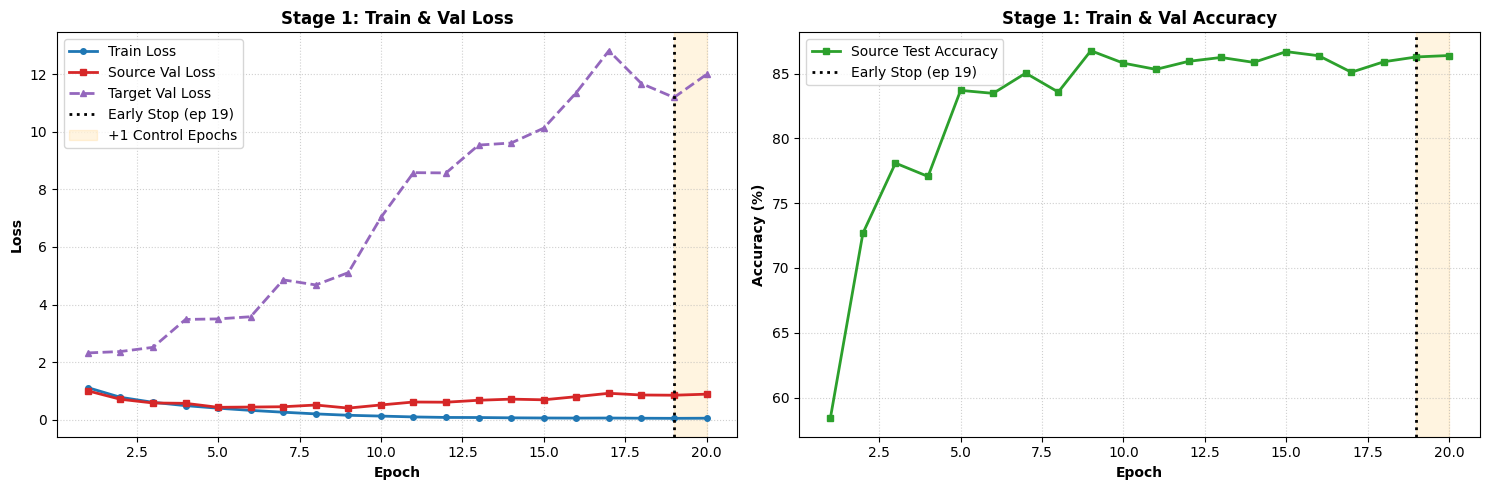

Stage 1 loss & accuracy curves saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_loss_accuracy_curves.png


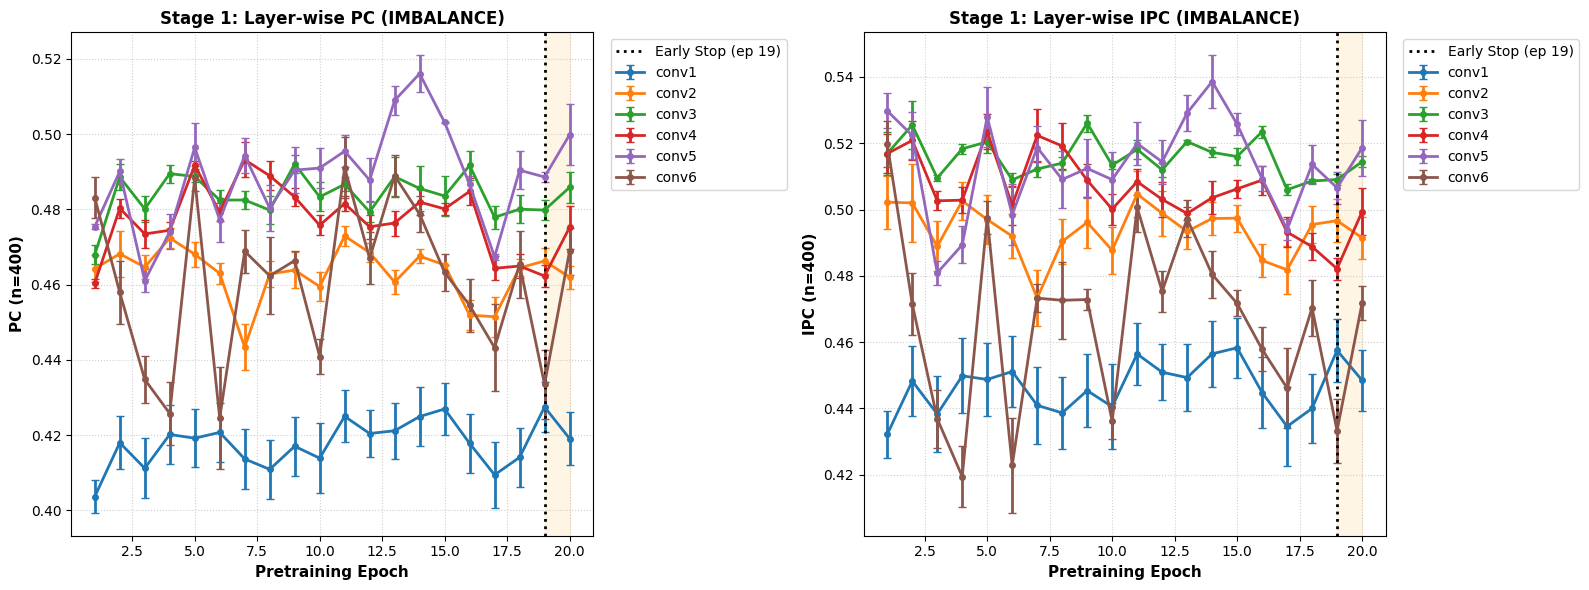

Stage 1 PC/IPC by layer saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_pc_ipc_by_layer.png


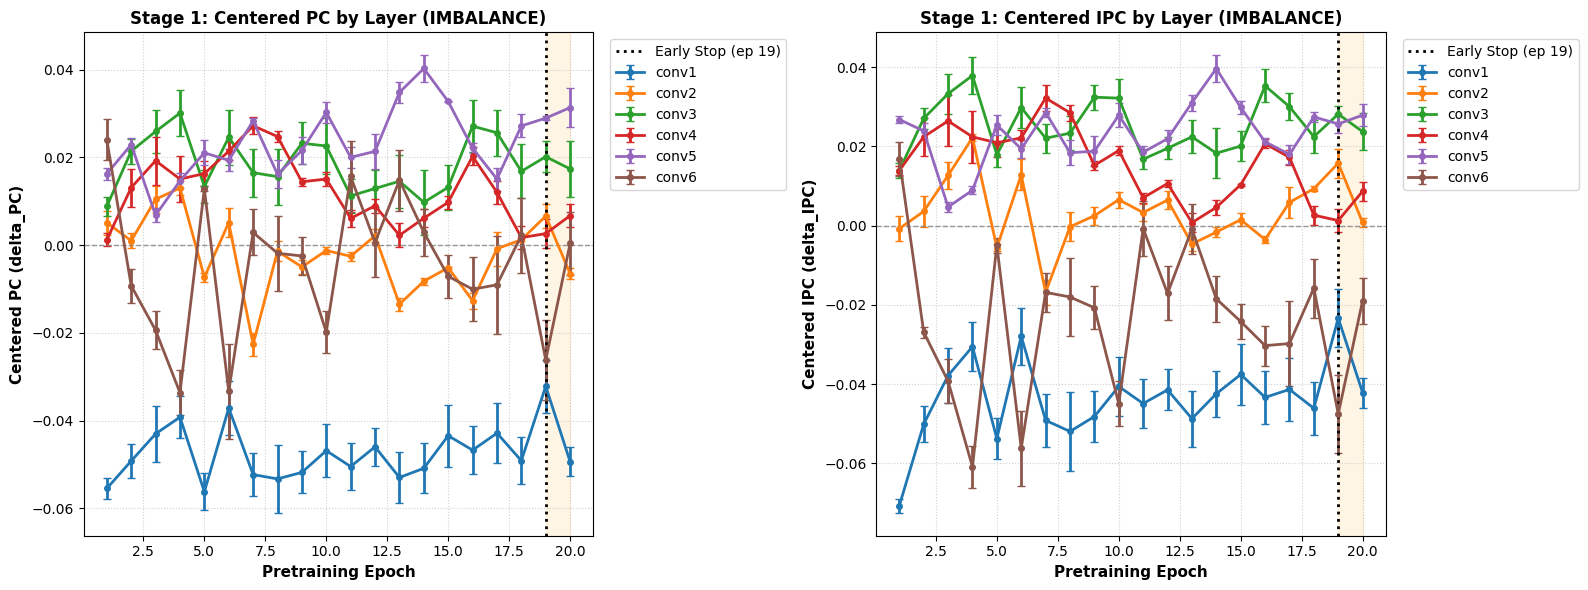

Stage 1 centered PC/IPC by layer saved to: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_centered_pc_ipc_by_layer.png


{'curves_path': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_loss_accuracy_curves.png',
 'profiles_path': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_pc_ipc_by_layer.png',
 'centered_path': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/plot_stage1_training_and_pc_ipc_profiles/01e313134eeb/stage1_centered_pc_ipc_by_layer.png'}

In [13]:
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

params["overwrite"]=True
plot_stage1_training_and_pc_ipc_profiles(params)

In [14]:
import json
from pathlib import Path
import pc_statistics


def _format_aligned_table(headers, rows):
    widths = [
        max(len(str(headers[i])), *(len(str(row[i])) for row in rows))
        for i in range(len(headers))
    ]

    def fmt_row(row):
        return " | ".join(str(row[i]).ljust(widths[i]) for i in range(len(headers)))

    separator = "-+-".join("-" * w for w in widths)
    return "\n".join([fmt_row(headers), separator] + [fmt_row(row) for row in rows])


def _fmt_val(val, fmt=".4f"):
    if val is None:
        return "n/a"
    return format(float(val), fmt)


@experiment_log(
    keys=[
        "experiment_case", "pc_sample_size", "num_replications",
        "use_real_cifar10", "pretrain_epochs", "early_stop_patience",
        "post_early_stop_epochs", "learning_rate_source", "target_epochs",
        "target_patience", "learning_rate_target", "feature_extraction",
        "ft_sample_size", "best_model_criterion", "seed", "mode",
    ],
    param="params",
    root=None,
)
def print_stage1_pc_ipc_correlations_by_epoch(params, log_path=None):
    """Печатает по эпохам среднюю корреляцию по слоям для PC и IPC,
    а также обычную и ранговую корреляцию между PC и IPC из файлов отчётов."""

    stage1_log_dir = run_stage1_pretraining.read_logs(params)
    if stage1_log_dir is None:
        raise FileNotFoundError(
            f"Stage 1 log not found for params: "
            f"case={params.get('experiment_case', '?')}, seed={params.get('seed', '?')}"
        )

    stage1_dir = Path(stage1_log_dir)
    csv_path = stage1_dir / "pc_ipc_layer_profiles.csv"

    corr_json_path = stage1_dir / "pc_ipc_correlation_report.json"
    if corr_json_path.exists():
        corr_data = json.loads(corr_json_path.read_text(encoding="utf-8"))
    else:
        if not csv_path.exists():
            raise FileNotFoundError(f"CSV не найден: {csv_path}")
        corr_data = pc_statistics.compute_and_save_correlation(
            log_dir=str(stage1_dir),
            csv_path=str(csv_path),
        )["corr_data"]

    stat_json_path = stage1_dir / "pc_statistics_report.json"
    if stat_json_path.exists():
        stat_report = json.loads(stat_json_path.read_text(encoding="utf-8"))
    else:
        if not csv_path.exists():
            raise FileNotFoundError(f"CSV не найден: {csv_path}")
        stat_report = pc_statistics.compute_and_save(
            log_dir=str(stage1_dir),
            csv_path=str(csv_path),
            params=params,
        )["report"]

    # Обычная корреляция между PC и IPC из файла отчёта (если сохранён)
    pc_ipc_corr_report_path = stage1_dir / "pc_ipc_between_correlation_report.json"
    between_corr_by_epoch = {}
    if pc_ipc_corr_report_path.exists():
        between_data = json.loads(pc_ipc_corr_report_path.read_text(encoding="utf-8"))
        between_corr_by_epoch = between_data.get("by_epoch", between_data)

    epochs = corr_data.get("epochs") or stat_report.get("epochs") or []
    epoch_stats = stat_report.get("epoch_stats", {})

    headers = [
        "epoch",
        "mean_r_PC",
        "mean_r_IPC",
        "corr_PC_IPC",
        "spearman_PC_IPC",
    ]
    rows = []
    for ep in epochs:
        ep_key = str(ep)
        pc_mean_r = corr_data.get("pc", {}).get(ep_key, {}).get("mean_r")
        ipc_mean_r = corr_data.get("ipc", {}).get(ep_key, {}).get("mean_r")
        spearman_r = epoch_stats.get(ep_key, {}).get("rho_pc_ipc")

        ep_between = between_corr_by_epoch.get(ep_key, {})
        if isinstance(ep_between, dict):
            pearson_r = ep_between.get(
                "pearson_r",
                ep_between.get("corr_pc_ipc", ep_between.get("r")),
            )
        else:
            pearson_r = ep_between

        rows.append([
            str(ep),
            _fmt_val(pc_mean_r),
            _fmt_val(ipc_mean_r),
            _fmt_val(pearson_r),
            _fmt_val(spearman_r),
        ])

    table = _format_aligned_table(headers, rows)
    print(table)

    return {
        "epochs": epochs,
        "corr_report_json": str(corr_json_path),
        "stats_report_json": str(stat_json_path),
    }

In [15]:
params = get_experiment_params(
    experiment_case="imbalance",
    pc_sample_size=400,
    num_replications=3,
    use_real_cifar10=True,
    pretrain_epochs=50,
    early_stop_patience=5,
    post_early_stop_epochs=1,
    learning_rate_source=0.001,
    target_epochs=50,
    target_patience=5,
    learning_rate_target=0.001,
    feature_extraction=True,
    ft_sample_size=10000,
    best_model_criterion="pc",
    seed=43,
)

params["overwrite"]=True
print_stage1_pc_ipc_correlations_by_epoch(params)

Results Directory: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
Mode: imbalance | Sample sizes: 400 | Replications: 3
Post early-stopping control epochs: 1
Random seed fixed: 43

=== ВСЕ ПАРАМЕТРЫ ЭКСПЕРИМЕНТА ===
experiment_case: imbalance
pc_sample_size: 400
num_replications: 3
use_real_cifar10: True
pretrain_epochs: 50
early_stop_patience: 5
post_early_stop_epochs: 1
learning_rate_source: 0.001
target_epochs: 50
target_patience: 5
learning_rate_target: 0.001
feature_extraction: True
ft_sample_size: 10000
best_model_criterion: pc
mode: 4_epochs
notebook_name: pretrained_stat
results_dir: /content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat
seed: 43

epoch | mean_r_PC | mean_r_IPC | corr_PC_IPC | spearman_PC_IPC
------+-----------+------------+-------------+----------------
1     | 0.4845    | 0.8619     | n/a         | 0.7714         
2     | 0.6416    | 0.8648     | n/a         | 0.9429         
3     | -0.0763   | 0.1370     | n/a    

{'epochs': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20],
 'corr_report_json': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage1_pretraining/7a69dae869fb/pc_ipc_correlation_report.json',
 'stats_report_json': '/content/drive/MyDrive/user/goit/Diplom/var1_Di/code/Di2/pretrained_stat/run_stage1_pretraining/7a69dae869fb/pc_statistics_report.json'}